<a href="https://colab.research.google.com/github/ibuscio/taller_deeplearning/blob/tarea_2/Tarea_2_letra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarea 2 - Taller de Deep Learning

**Fecha de entrega:** 22/11/2026  
**Puntaje máximo:** 15 puntos  
**Alumno(s):**
- [Nombre1 y Apellido1]
- [Nombre2 y Apellido2]
- [Nombre3 y Apellido3]


## Introducción

El objetivo de esta tarea es evaluar su capacidad para aplicar **redes neuronales recurrentes** a un problema de clasificación de secuencias. En particular, vamos a trabajar en **reconocimiento de palabras habladas**: a partir de un clip de audio de un segundo, el modelo debe identificar qué palabra se pronunció.

### Dataset

El dataset a utilizar es **Speech Commands v0.02**, publicado por Google bajo licencia [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Contiene 105.829 clips de audio de hasta un segundo, grabados por más de 2.600 personas con sus propios micrófonos. Cada clip contiene una única palabra en inglés, de un total de 35:

`backward`, `bed`, `bird`, `cat`, `dog`, `down`, `eight`, `five`, `follow`, `forward`, `four`, `go`, `happy`, `house`, `learn`, `left`, `marvin`, `nine`, `no`, `off`, `on`, `one`, `right`, `seven`, `sheila`, `six`, `stop`, `three`, `tree`, `two`, `up`, `visual`, `wow`, `yes`, `zero`.

El dataset se descarga desde http://download.tensorflow.org/data/speech_commands_v0.02.tar.gz (2,3 GB comprimido, 3,3 GB descomprimido). Al descomprimirlo encontrarán:

- Una carpeta por palabra, con archivos `.wav` mono de 16 kHz y 16 bits. El nombre de cada archivo tiene la forma `<hablante>_nohash_<n>.wav`, donde `<hablante>` identifica a la persona que grabó el clip.
- Los archivos `validation_list.txt` y `testing_list.txt`, con las rutas de los clips de validación y de test.
- La carpeta `_background_noise_/`, con grabaciones largas de ruido (ambientes domésticos, ruido blanco y ruido rosa). Estas grabaciones no tienen etiqueta y no forman parte de ninguna de las 35 clases.
- Los archivos `README.md` y `LICENSE`.

La descarga y descompresión deben quedar en el notebook, de forma que quien corrija pueda reproducir todo el pipeline desde cero. El dataset se describe en el siguiente artículo, que deben citar en la entrega:

> P. Warden. *Speech Commands: A Dataset for Limited-Vocabulary Speech Recognition*. arXiv:1804.03209, 2018. https://arxiv.org/abs/1804.03209

### Partición de datos

Speech Commands define una partición oficial, que deben usar **sin modificarla**:

- Los clips listados en `validation_list.txt` forman el conjunto de **validación**.
- Los clips listados en `testing_list.txt` forman el conjunto de **test**.
- El resto de los clips forma el conjunto de **entrenamiento**.

La partición oficial asigna todos los clips de una misma persona a un único conjunto, de modo que el modelo se evalúa con voces que no escuchó durante el entrenamiento. Todas las decisiones de diseño (representación del audio, arquitectura, hiperparámetros, early stopping, selección de modelo) se toman con el conjunto de validación. El conjunto de test se usa **únicamente** para reportar las métricas finales del modelo elegido, y se evalúa una sola vez, en la sección 8. Ajustar hiperparámetros o seleccionar modelos usando el conjunto de test será penalizado.

### Tarea

Tienen libertad sobre cómo implementar y resolver el problema, así como sobre las técnicas y herramientas que quieran usar, siempre que cumplan las restricciones indicadas más abajo. Recomendamos usar Google Colab por simplicidad, pero pueden implementarlo en sus máquinas si así lo prefieren. La entrega debe realizarse en formato `.ipynb` (Jupyter Notebook) **con las celdas ya ejecutadas**.

Un clip de un segundo tiene 16.000 muestras. Recorrerlo con una red recurrente de a una muestra por paso es costoso y difícil de entrenar. Parte central de la tarea es decidir cómo presentar cada clip a la red como una secuencia (cuántos pasos tiene y qué información contiene cada paso) y justificar esa decisión con la exploración de los datos y con experimentos. Deben comparar en validación al menos dos representaciones distintas, con la misma arquitectura.

### Restricciones

- No se permite utilizar modelos pre-entrenados; cada modelo debe ser implementado desde cero.
- **El modelo final debe ser recurrente.** Las capas que combinan información de distintos instantes de tiempo deben ser recurrentes: `nn.RNN`, `nn.LSTM`, `nn.GRU` o una celda implementada por ustedes, en cualquiera de sus variantes (apiladas, bidireccionales, etc.). Se permite procesar cada paso por separado antes de la red recurrente (por ejemplo, con una capa lineal o un MLP aplicado a cada paso) y combinar las salidas de la red recurrente para clasificar. No se permiten convoluciones a lo largo del eje temporal ni Transformers.
- **Comparación de celdas recurrentes.** Deben entrenar al menos una RNN simple (`nn.RNN`), una LSTM y una GRU con la misma representación de entrada y el resto de la configuración lo más parecida posible (cantidad de capas, tamaño del estado oculto, optimizador, cantidad de épocas). A partir de esa comparación, y de los experimentos adicionales que consideren necesarios, deben elegir el tipo de red recurrente del modelo final y justificar la elección con métricas en validación, cantidad de parámetros, tiempo de entrenamiento y estabilidad del entrenamiento. Si alguna variante no logra aprender, deben explicar por qué.
- La **accuracy en test** del modelo final debe ser de **al menos 80 %**. Se espera que alcancen 90 % o más. Este requisito aplica al conjunto de test oficial.
- **Grabaciones propias.** El grupo debe grabar cada una de las 35 palabras, pronunciadas en inglés, **al menos una vez**. Lo ideal es que cada integrante grabe cada palabra al menos una vez. Las grabaciones deben tener el mismo formato que los clips del dataset (WAV mono de 16 kHz y 16 bits, de hasta un segundo, con una única palabra por archivo) y organizarse como `grabaciones/<palabra>/<integrante>_<n>.wav`. Estas grabaciones **no se usan para entrenar ni para tomar decisiones de diseño**: se usan únicamente para evaluar el modelo final, además del conjunto de test oficial. La grabación, la conversión de formato, el cambio de frecuencia de muestreo y el recorte de los archivos se hacen **fuera del notebook** y no deben incluirse en él. El notebook solo lee los archivos `.wav` ya listos de la carpeta `grabaciones/` y les aplica la misma representación que a los clips del dataset.
- Se requiere realizar un **análisis exploratorio de los datos**, que incluya la duración y el volumen de los clips, la distribución de clases en entrenamiento, validación y test, la cantidad de hablantes y de clips por hablante, y ejemplos de al menos 3 clases (gráficas de la señal y audio reproducible en el notebook, por ejemplo con `IPython.display.Audio`). Las decisiones de preprocesamiento y de entrenamiento deben tomarse en base a ese análisis, e indicar qué resultado del análisis justifica cada una.
- Deben fijar una **semilla** para que los resultados sean reproducibles, y reportar el hardware utilizado (GPU/CPU) y el tiempo de entrenamiento de cada experimento.
- Pueden usar `utils.py` y todo el material dado en clase, siempre y cuando entiendan lo que están usando. Pueden ser consultados sobre cualquier parte del código entregado.

### Reporte

Deben reportar, sobre el conjunto de test, las siguientes métricas del modelo final:

- **Accuracy**.
- **Precision, recall y F1-score** con promedio **macro**.
- **Precision, recall y F1-score por clase**.
- **Matriz de confusión**, con un análisis de al menos los 3 pares de palabras que más se confunden entre sí: cantidad de errores de cada par y una hipótesis de la causa.

Sobre las grabaciones propias deben reportar la accuracy total y por integrante, qué palabras se clasificaron mal y con qué palabra se confundieron, y una comparación con los resultados en el conjunto de test oficial, con un análisis de las diferencias.

Al final del notebook debe haber una **celda de resumen** con el tipo de red recurrente del modelo final, la accuracy y el F1-score macro en el test oficial, y la accuracy en las grabaciones propias.

También se espera poder observar la evolución del modelo (loss y accuracy en entrenamiento y validación) a medida que se entrena, mediante logs y gráficas.

### Evidencia de experimentos

Deben presentar en el notebook evidencia de los experimentos. Esto incluye:

- Un mínimo de **6 experimentos** con configuraciones distintas. La comparación de celdas recurrentes cuenta dentro de estos 6.
- Curvas de loss y accuracy en entrenamiento y validación de cada experimento. Pueden agrupar las curvas de varios experimentos en una misma gráfica.
- Una **tabla resumen** en el notebook que compare los experimentos: configuración, cantidad de parámetros, métricas en validación, tiempo de entrenamiento y hardware.
- Una justificación de cuál es el modelo final elegido y por qué.

### Lecturas sugeridas

- H. Fayek (2016). [*Speech Processing for Machine Learning: Filter banks, Mel-Frequency Cepstral Coefficients (MFCCs) and What's In-Between*](https://haythamfayek.com/2016/04/21/speech-processing-for-machine-learning.html). Introducción a la representación digital de la voz y a sus transformaciones más comunes.
- R. Pascanu, T. Mikolov e Y. Bengio (2013). *On the difficulty of training recurrent neural networks*. [arXiv:1211.5063](https://arxiv.org/abs/1211.5063).
- J. Chung, C. Gulcehre, K. Cho e Y. Bengio (2014). *Empirical Evaluation of Gated Recurrent Neural Networks on Sequence Modeling*. [arXiv:1412.3555](https://arxiv.org/abs/1412.3555).

## Formato de entrega

- La tarea se realiza en **grupos de 2 o 3 personas**.
- Se entrega este notebook con **todas las celdas ejecutadas**, junto con los archivos auxiliares que use (por ejemplo `utils.py`). **No se entregan ni los pesos de los modelos ni el dataset**. Las grabaciones propias sí se entregan, en la carpeta `grabaciones/` junto al notebook. El notebook debe poder ejecutarse de principio a fin con lo entregado (`Restart & Run All`), incluyendo la descarga del dataset.
- El notebook principal **no puede superar las 30 páginas** una vez exportado a PDF.
- Se recomienda seguir la estructura sugerida más abajo. Pueden agregar subsecciones, pero no eliminar secciones.

### Uso de herramientas de IA

Se permite el uso de herramientas de IA (ChatGPT, Copilot, Claude, etc.) como apoyo. Sin embargo:

- Los alumnos son **responsables de todo lo que entregan** y deben **entender** cada parte del código y del análisis. Pueden ser consultados sobre cualquier parte de la entrega.
- Se espera que apliquen los conocimientos vistos en clase para guiar y evaluar lo que estas herramientas producen. Un notebook que no refleje los contenidos del curso, o que contenga código que el grupo no puede explicar, puede ser penalizado.

### Rúbrica

| Ítem | Puntos |
|---|---|
| Carga del dataset y análisis exploratorio | 1,5 |
| Representación del audio como secuencia | 1,5 |
| Modelo, pipeline de entrenamiento y uso de la partición | 2 |
| Comparación de RNN simple, LSTM y GRU y elección del tipo de celda | 3 |
| Evaluación en test, métricas y análisis de errores | 2 |
| Grabaciones propias y evaluación del modelo con ellas | 2 |
| Desempeño en test: 1 punto con accuracy de 90 % o más, 0,5 puntos entre 80 % y 90 % | 1 |
| Experimentos, tabla resumen y conclusiones | 2 |
| **Total** | **15** |

Una accuracy en test menor a 80 % no cumple el requisito mínimo de la tarea.


---

## 1. Setup

_Imports, instalación de dependencias, semilla y dispositivo._

In [1]:
!pip install -q torchinfo
from torchinfo import summary

In [2]:
# Imports estándar y científicos
import os
import sys
import time
import math
import random
import tarfile
import urllib.request
import platform
from pathlib import Path
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import wavfile
from tqdm.auto import tqdm
from IPython.display import Audio, display

# PyTorch y audio
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchaudio
import torchaudio.transforms as T

# Métricas de evaluación
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

# Configuración estética de gráficos
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

# 1. Fijar semilla para reproducibilidad
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(SEED)

# 2. Detección y reporte de dispositivo / hardware
if torch.cuda.is_available():
    device = torch.device('cuda')
    hw_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    hw_summary = f"GPU: {hw_name} ({vram_gb:.1f} GB VRAM)"
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    device = torch.device('mps')
    hw_summary = f"Apple Silicon MPS ({platform.processor()})"
else:
    device = torch.device('cpu')
    hw_summary = f"CPU ({platform.processor() or platform.machine()})"

print(f"=== Configuración del Entorno ===")
print(f"Semilla global      : {SEED}")
print(f"Dispositivo activo  : {device} -> {hw_summary}")
print(f"CPUs disponibles    : {os.cpu_count()}")
print(f"PyTorch versión     : {torch.__version__}")
print(f"Torchaudio versión  : {torchaudio.__version__}")

=== Configuración del Entorno ===
Semilla global      : 42
Dispositivo activo  : cuda -> GPU: Tesla T4 (14.6 GB VRAM)
CPUs disponibles    : 2
PyTorch versión     : 2.14.1+cu130
Torchaudio versión  : 2.11.0+cu130


In [3]:
# Descargar el archivo utils.py desde Google Drive usando gdown solo si no existe
import os
import gdown

output = 'utils.py'

if os.path.exists(output):
    print(f"El archivo '{output}' ya existe en el directorio. Se omite la descarga.")
else:
    print(f"Descargando '{output}'...")
    file_id = '1MiV6TnWbpfIob70ISnxnNtZ7NeHlEoWW'
    url = f'https://drive.google.com/uc?id={file_id}'
    gdown.download(url, output, quiet=False)

Descargando 'utils.py'...


Downloading...
From (original): https://drive.google.com/uc?id=1MiV6TnWbpfIob70ISnxnNtZ7NeHlEoWW
From (redirected): https://drive.google.com/uc?id=1MiV6TnWbpfIob70ISnxnNtZ7NeHlEoWW&confirm=t&uuid=14c35c45-3c26-4326-a3ab-21378e27b15c
To: /content/utils.py
100%|██████████| 18.2k/18.2k [00:00<00:00, 41.7MB/s]


## 2. Descarga y carga del dataset

_Descarga y descompresión de `speech_commands_v0.02.tar.gz`, lectura de los clips y de las listas de validación y test._

Utilizamos el dataset **Speech Commands v0.02** propuesto por:
> P. Warden. *Speech Commands: A Dataset for Limited-Vocabulary Speech Recognition*. arXiv:1804.03209, 2018. https://arxiv.org/abs/1804.03209

In [4]:
# Configuración de rutas y descarga reproducible
DATA_URL = "http://download.tensorflow.org/data/speech_commands_v0.02.tar.gz"
DATA_ROOT = Path("data")
ARCHIVE_PATH = DATA_ROOT / "speech_commands_v0.02.tar.gz"
DATASET_DIR = DATA_ROOT / "speech_commands_v0.02"

DATA_ROOT.mkdir(parents=True, exist_ok=True)

# Verificamos si ya fue descomprimido comprobando la existencia de validation_list.txt
if not (DATASET_DIR / "validation_list.txt").exists():
    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    if not ARCHIVE_PATH.exists():
        print(f"Descargando Speech Commands v0.02 desde {DATA_URL} ...")
        with tqdm(unit='B', unit_scale=True, unit_divisor=1024, miniters=1, desc="Descargando") as pbar:
            def report_hook(block_num, block_size, total_size):
                if total_size > 0:
                    pbar.total = total_size
                pbar.update(block_size)
            urllib.request.urlretrieve(DATA_URL, ARCHIVE_PATH, reporthook=report_hook)
        print("Descarga completada.")
    else:
        print(f"Archivo comprimido ya existe en {ARCHIVE_PATH}.")

    print(f"Descomprimiendo en {DATASET_DIR} ...")
    with tarfile.open(ARCHIVE_PATH, "r:gz") as tar:
        tar.extractall(path=DATASET_DIR)
    print("Descompresión finalizada.")
else:
    print(f"Dataset ya disponible y descomprimido en: {DATASET_DIR}")

Descargando Speech Commands v0.02 desde http://download.tensorflow.org/data/speech_commands_v0.02.tar.gz ...


Descargando: 0.00B [00:00, ?B/s]

Descarga completada.
Descomprimiendo en data/speech_commands_v0.02 ...


/tmp/ipykernel_473/630385298.py:26: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=DATASET_DIR)


Descompresión finalizada.


In [5]:
# Definición oficial de las 35 clases (ordenadas alfabéticamente)
CLASSES = [
    'backward', 'bed', 'bird', 'cat', 'dog', 'down', 'eight', 'five', 'follow',
    'forward', 'four', 'go', 'happy', 'house', 'learn', 'left', 'marvin', 'nine',
    'no', 'off', 'on', 'one', 'right', 'seven', 'sheila', 'six', 'stop', 'three',
    'tree', 'two', 'up', 'visual', 'wow', 'yes', 'zero'
]
assert len(CLASSES) == 35, f"Se esperaban 35 clases, se encontraron {len(CLASSES)}"

CLASS_TO_IDX = {cls_name: idx for idx, cls_name in enumerate(CLASSES)}
IDX_TO_CLASS = {idx: cls_name for idx, cls_name in enumerate(CLASSES)}

# Lectura de las listas oficiales de validación y test (rutas relativas tipo 'word/speaker_nohash_0.wav')
with open(DATASET_DIR / "validation_list.txt", "r") as f:
    val_set_rel = set(line.strip() for line in f if line.strip())

with open(DATASET_DIR / "testing_list.txt", "r") as f:
    test_set_rel = set(line.strip() for line in f if line.strip())

# Recorremos las carpetas de las 35 palabras para indexar todos los clips y su partición oficial
records = []
for label in CLASSES:
    folder = DATASET_DIR / label
    if not folder.exists():
        raise FileNotFoundError(f"No se encontró la carpeta de la clase: {folder}")
    for wav_path in sorted(folder.glob("*.wav")):
        rel_path = f"{label}/{wav_path.name}"
        speaker_id = wav_path.stem.split("_nohash_")[0]
        if rel_path in val_set_rel:
            split = "val"
        elif rel_path in test_set_rel:
            split = "test"
        else:
            split = "train"
        records.append({
            "rel_path": rel_path,
            "abs_path": str(wav_path),
            "label": label,
            "label_idx": CLASS_TO_IDX[label],
            "speaker_id": speaker_id,
            "split": split
        })

df_clips = pd.DataFrame(records)

# Archivos en _background_noise_ (no pertenecen a ninguna clase)
bg_noise_dir = DATASET_DIR / "_background_noise_"
bg_noise_files = sorted(bg_noise_dir.glob("*.wav")) if bg_noise_dir.exists() else []

print(f"Total de clips indexados (35 clases): {len(df_clips):,}")
print("\nConteo por partición oficial:")
for s in ["train", "val", "test"]:
    cnt = (df_clips["split"] == s).sum()
    pct = 100.0 * cnt / len(df_clips)
    print(f"  - {s:<5}: {cnt:>6,} clips ({pct:.2f}%)")
print(f"\nGrabaciones de ruido de fondo (_background_noise_): {len(bg_noise_files)} archivos")

Total de clips indexados (35 clases): 105,829

Conteo por partición oficial:
  - train: 84,843 clips (80.17%)
  - val  :  9,981 clips (9.43%)
  - test : 11,005 clips (10.40%)

Grabaciones de ruido de fondo (_background_noise_): 6 archivos


## 3. Análisis exploratorio de datos

_Duración y volumen de los clips, distribución de clases en entrenamiento, validación y test, hablantes y clips por hablante, ejemplos de la señal y audio de al menos 3 clases. Conclusiones que guían el preprocesamiento._

### 3.1. Duración y volumen de los clips

Analizamos la frecuencia de muestreo, la cantidad de muestras (duración en segundos), el nivel de energía RMS (Root Mean Square) y la amplitud pico de los clips del dataset para verificar si existen audios más cortos de 1 segundo, silencios o variaciones fuertes de ganancia entre grabaciones.

Analizando duración y volumen de los clips (lectura multihilo)...


Procesando WAVs:   0%|          | 0/105829 [00:00<?, ?it/s]

Análisis completado en 33.7 s.

Frecuencias de muestreo presentes: [16000] Hz
Clips de exactamente 1.0 s (16.000 muestras): 95,394 (90.14%)
Clips menores a 1.0 s (< 16.000 muestras)  : 10,435 (9.86%)
Clips mayores a 1.0 s (> 16.000 muestras)  : 0


,duration_s,n_samples,rms,rms_db,peak
count,105829.0000,105829.0000,105829.0000,105829.0000,105829.0000
mean,0.9809,15694.8853,0.0702,-25.2578,0.5138
std,0.0718,1148.3722,0.0511,6.4541,0.2761
min,0.2133,3413.0000,0.0043,-47.4162,0.0053
1%,0.6037,9660.0000,0.0095,-40.4584,0.0587
5%,0.8359,13375.0000,0.0141,-37.0428,0.1057
25%,1.0000,16000.0000,0.0330,-29.6194,0.2711
50%,1.0000,16000.0000,0.0609,-24.3127,0.4995
75%,1.0000,16000.0000,0.0933,-20.6005,0.7527
95%,1.0000,16000.0000,0.1585,-15.9988,0.9940


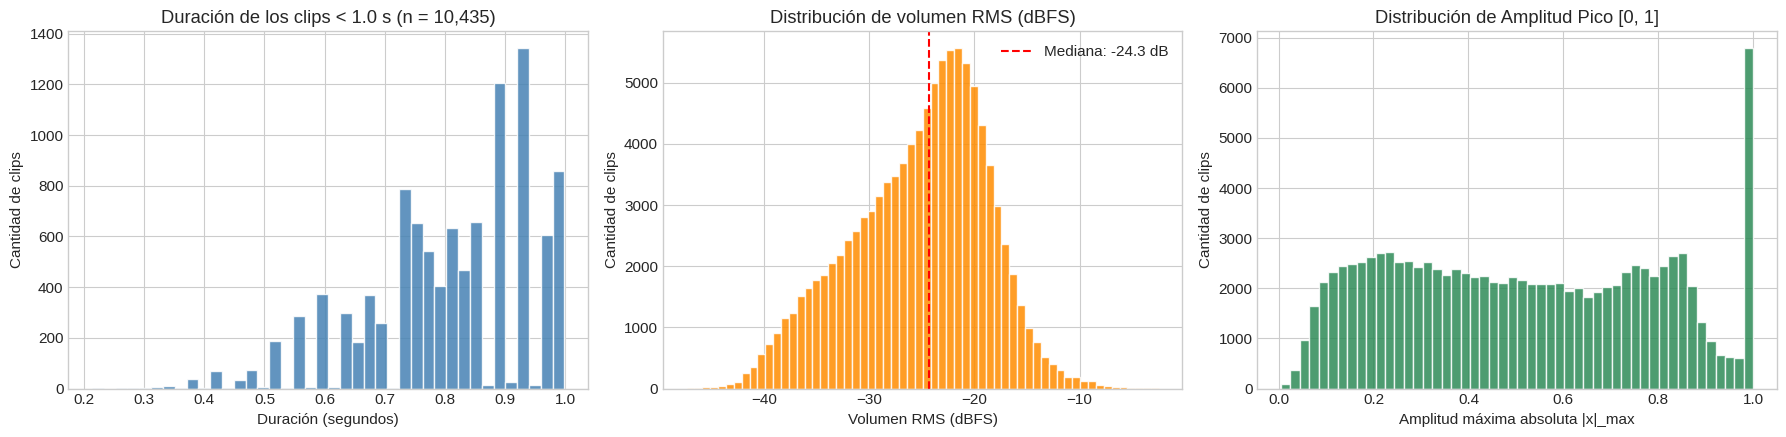

In [6]:
# Extracción paralela de duración y volumen sobre los clips del dataset
def analyze_wav_file(path_str: str):
    sr, data = wavfile.read(path_str)
    n_samples = len(data)
    duration_s = n_samples / float(sr)
    # Convertimos de int16 [-32768, 32767] a float32 en [-1.0, 1.0]
    x = data.astype(np.float32) / 32768.0
    rms = float(np.sqrt(np.mean(x ** 2)))
    peak = float(np.max(np.abs(x))) if n_samples > 0 else 0.0
    rms_db = 20.0 * math.log10(max(rms, 1e-7))
    return sr, n_samples, duration_s, rms, rms_db, peak

print("Analizando duración y volumen de los clips (lectura multihilo)...")
t0 = time.time()
with ThreadPoolExecutor(max_workers=min(16, (os.cpu_count() or 4) * 2)) as ex:
    stats_list = list(tqdm(
        ex.map(analyze_wav_file, df_clips["abs_path"].tolist(), chunksize=512),
        total=len(df_clips),
        desc="Procesando WAVs"
    ))

stats_arr = np.array(stats_list, dtype=np.float32)
df_clips["sr"] = stats_arr[:, 0].astype(int)
df_clips["n_samples"] = stats_arr[:, 1].astype(int)
df_clips["duration_s"] = stats_arr[:, 2]
df_clips["rms"] = stats_arr[:, 3]
df_clips["rms_db"] = stats_arr[:, 4]
df_clips["peak"] = stats_arr[:, 5]
print(f"Análisis completado en {time.time() - t0:.1f} s.\n")

# Resumen estadístico
exact_1s = (df_clips["n_samples"] == 16000).sum()
shorter_1s = (df_clips["n_samples"] < 16000).sum()
longer_1s = (df_clips["n_samples"] > 16000).sum()
print(f"Frecuencias de muestreo presentes: {df_clips['sr'].unique().tolist()} Hz")
print(f"Clips de exactamente 1.0 s (16.000 muestras): {exact_1s:,} ({100*exact_1s/len(df_clips):.2f}%)")
print(f"Clips menores a 1.0 s (< 16.000 muestras)  : {shorter_1s:,} ({100*shorter_1s/len(df_clips):.2f}%)")
print(f"Clips mayores a 1.0 s (> 16.000 muestras)  : {longer_1s:,}")

display(df_clips[["duration_s", "n_samples", "rms", "rms_db", "peak"]].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(4))

# Gráficas de duración y volumen
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1. Distribución de duraciones en clips < 1.0 s
short_durations = df_clips.loc[df_clips["n_samples"] < 16000, "duration_s"]
axes[0].hist(short_durations, bins=40, color="steelblue", edgecolor="white", alpha=0.85)
axes[0].set_title(f"Duración de los clips < 1.0 s (n = {len(short_durations):,})")
axes[0].set_xlabel("Duración (segundos)")
axes[0].set_ylabel("Cantidad de clips")

# 2. Distribución de volumen RMS (en dBFS)
axes[1].hist(df_clips["rms_db"], bins=60, color="darkorange", edgecolor="white", alpha=0.85)
axes[1].axvline(df_clips["rms_db"].median(), color="red", linestyle="--", label=f"Mediana: {df_clips['rms_db'].median():.1f} dB")
axes[1].set_title("Distribución de volumen RMS (dBFS)")
axes[1].set_xlabel("Volumen RMS (dBFS)")
axes[1].set_ylabel("Cantidad de clips")
axes[1].legend()

# 3. Distribución de amplitud pico normalizada
axes[2].hist(df_clips["peak"], bins=50, color="seagreen", edgecolor="white", alpha=0.85)
axes[2].set_title("Distribución de Amplitud Pico [0, 1]")
axes[2].set_xlabel("Amplitud máxima absoluta |x|_max")
axes[2].set_ylabel("Cantidad de clips")

plt.tight_layout()
plt.show()

### 3.2. Distribución de clases en entrenamiento, validación y test

Examinamos la cantidad de muestras y la proporción relativa de cada una de las 35 palabras en las tres particiones oficiales.

Clase con más muestras   : 'five' (4,052 clips)
Clase con menos muestras : 'forward' (1,557 clips)
Ratio máx / mín          : 2.60x


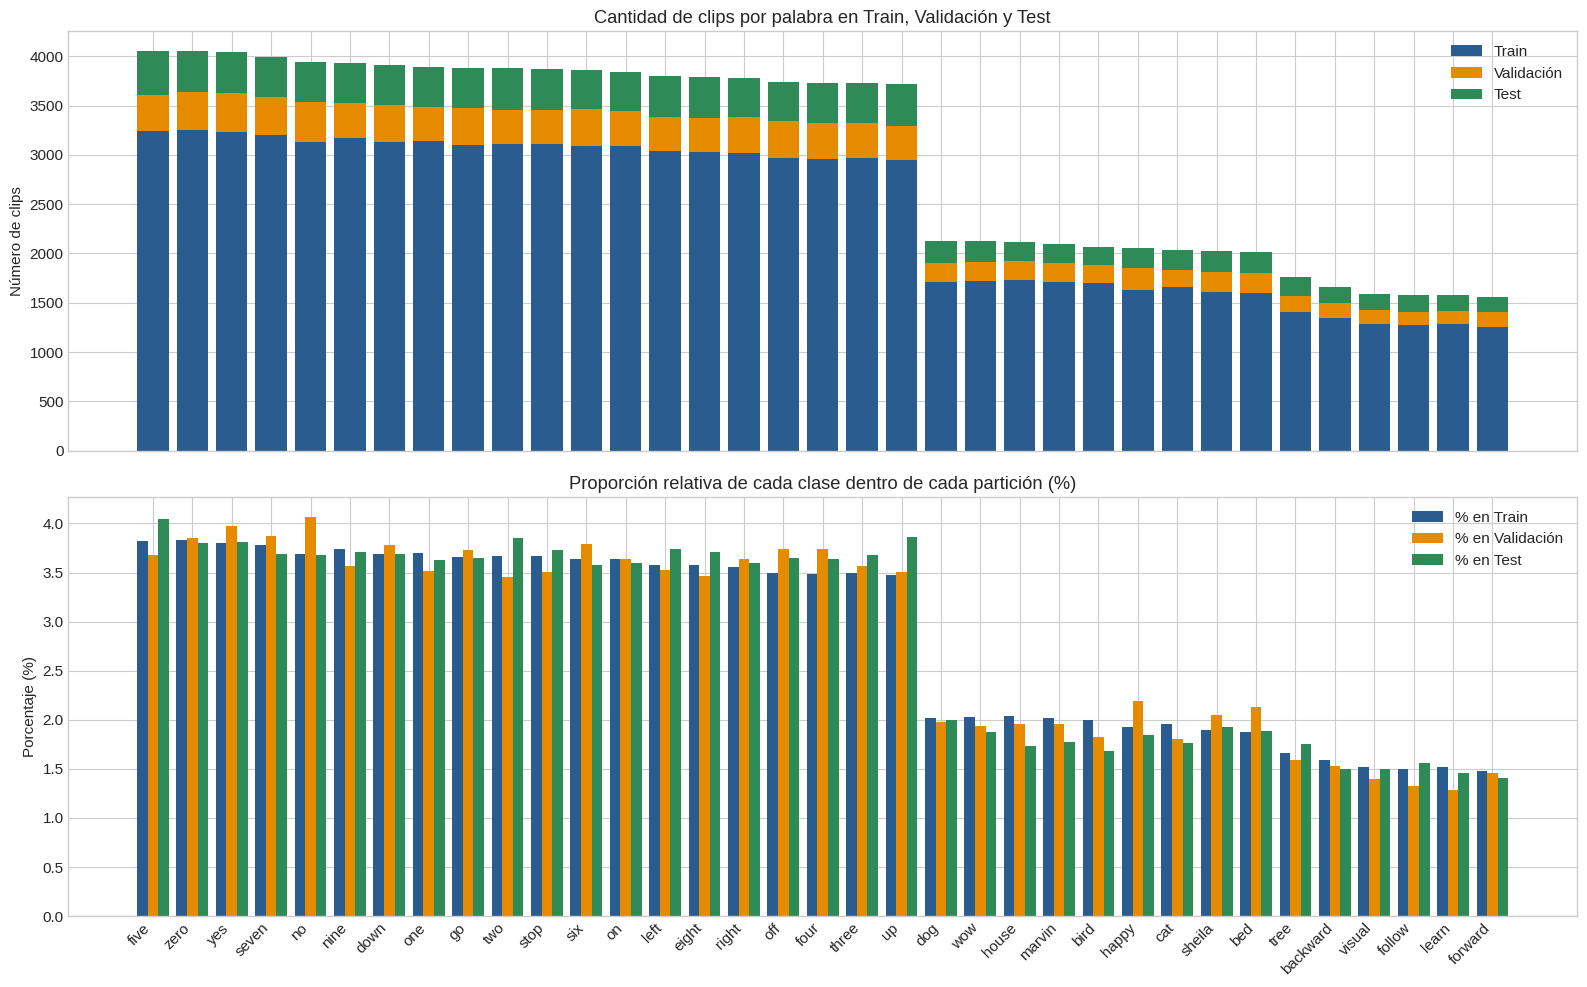

In [7]:
# Tabla cruzada de clases por partición
class_split_counts = pd.crosstab(df_clips["label"], df_clips["split"])[["train", "val", "test"]]
class_split_counts["total"] = class_split_counts.sum(axis=1)
class_split_counts = class_split_counts.sort_values("total", ascending=False)

print(f"Clase con más muestras   : '{class_split_counts.index[0]}' ({class_split_counts['total'].iloc[0]:,} clips)")
print(f"Clase con menos muestras : '{class_split_counts.index[-1]}' ({class_split_counts['total'].iloc[-1]:,} clips)")
print(f"Ratio máx / mín          : {class_split_counts['total'].iloc[0] / class_split_counts['total'].iloc[-1]:.2f}x")

# Gráfico de barras apiladas por clase y gráfica de proporciones relativas
fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

x_pos = np.arange(len(class_split_counts))
labels_ordered = class_split_counts.index.tolist()

# Subplot 1: Cantidad absoluta por split
axes[0].bar(x_pos, class_split_counts["train"], label="Train", color="#2b5c8f")
axes[0].bar(x_pos, class_split_counts["val"], bottom=class_split_counts["train"], label="Validación", color="#e68a00")
axes[0].bar(
    x_pos,
    class_split_counts["test"],
    bottom=class_split_counts["train"] + class_split_counts["val"],
    label="Test",
    color="#2e8b57"
)
axes[0].set_title("Cantidad de clips por palabra en Train, Validación y Test")
axes[0].set_ylabel("Número de clips")
axes[0].legend()

# Subplot 2: Proporción relativa de cada clase dentro de cada split (%)
class_split_pct = class_split_counts[["train", "val", "test"]].div(class_split_counts[["train", "val", "test"]].sum(axis=0), axis=1) * 100.0
width = 0.27
axes[1].bar(x_pos - width, class_split_pct["train"], width=width, label="% en Train", color="#2b5c8f")
axes[1].bar(x_pos, class_split_pct["val"], width=width, label="% en Validación", color="#e68a00")
axes[1].bar(x_pos + width, class_split_pct["test"], width=width, label="% en Test", color="#2e8b57")
axes[1].set_title("Proporción relativa de cada clase dentro de cada partición (%)")
axes[1].set_ylabel("Porcentaje (%)")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(labels_ordered, rotation=45, ha="right")
axes[1].legend()

plt.tight_layout()
plt.show()

### 3.3. Cantidad de hablantes y clips por hablante

Verificamos cuántos hablantes únicos (`speaker_id`) participaron en el dataset, cuántos clips grabó cada uno y comprobamos si la partición oficial mantiene hablantes disjuntos entre entrenamiento, validación y test.

Total de hablantes únicos en el dataset: 2,618
  - Hablantes en train: 2,112
  - Hablantes en val  : 256
  - Hablantes en test : 250

Intersección de hablantes entre particiones:
  - Train ∩ Val  : 0
  - Train ∩ Test : 0
  - Val   ∩ Test : 0

Estadísticas de clips grabados por hablante:


,count,mean,std,min,10%,25%,50%,75%,90%,99%,max
clips_por_hablante,2618.0,40.42,36.92,1.0,7.0,25.0,30.0,30.0,111.0,130.0,316.0


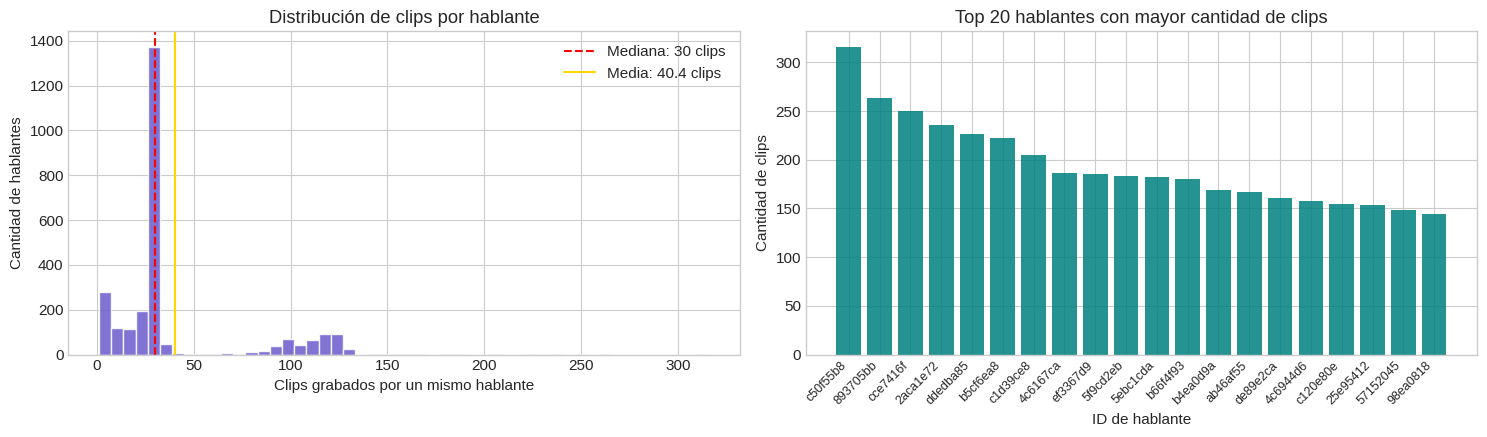

In [8]:
# Análisis de hablantes
total_speakers = df_clips["speaker_id"].nunique()
speakers_by_split = {s: set(df_clips.loc[df_clips["split"] == s, "speaker_id"]) for s in ["train", "val", "test"]}

print(f"Total de hablantes únicos en el dataset: {total_speakers:,}")
for s in ["train", "val", "test"]:
    print(f"  - Hablantes en {s:<5}: {len(speakers_by_split[s]):,}")

# Verificación de intersección de hablantes entre splits
inter_train_val = len(speakers_by_split["train"] & speakers_by_split["val"])
inter_train_test = len(speakers_by_split["train"] & speakers_by_split["test"])
inter_val_test = len(speakers_by_split["val"] & speakers_by_split["test"])
print(f"\nIntersección de hablantes entre particiones:")
print(f"  - Train ∩ Val  : {inter_train_val}")
print(f"  - Train ∩ Test : {inter_train_test}")
print(f"  - Val   ∩ Test : {inter_val_test}")

# Distribución de cantidad de clips por hablante
clips_per_speaker = df_clips.groupby("speaker_id").size()
print("\nEstadísticas de clips grabados por hablante:")
display(clips_per_speaker.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).to_frame(name="clips_por_hablante").T.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].hist(clips_per_speaker, bins=50, color="slateblue", edgecolor="white", alpha=0.85)
axes[0].axvline(clips_per_speaker.median(), color="red", linestyle="--", label=f"Mediana: {clips_per_speaker.median():.0f} clips")
axes[0].axvline(clips_per_speaker.mean(), color="gold", linestyle="-", label=f"Media: {clips_per_speaker.mean():.1f} clips")
axes[0].set_title("Distribución de clips por hablante")
axes[0].set_xlabel("Clips grabados por un mismo hablante")
axes[0].set_ylabel("Cantidad de hablantes")
axes[0].legend()

# Top 20 hablantes con más grabaciones
top20_speakers = clips_per_speaker.sort_values(ascending=False).head(20)
axes[1].bar(range(len(top20_speakers)), top20_speakers.values, color="teal", alpha=0.85)
axes[1].set_xticks(range(len(top20_speakers)))
axes[1].set_xticklabels(top20_speakers.index, rotation=45, ha="right", fontsize=9)
axes[1].set_title("Top 20 hablantes con mayor cantidad de clips")
axes[1].set_xlabel("ID de hablante")
axes[1].set_ylabel("Cantidad de clips")

plt.tight_layout()
plt.show()

### 3.4. Ejemplos de señales y audio reproducible

Visualizamos la señal en el dominio del tiempo y reproducimos el audio de **4 clases distintas** (`yes`, `stop`, `marvin`, `backward`) del conjunto de entrenamiento.

▶ Audio de ejemplo para clase 'yes' (yes/004ae714_nohash_0.wav):


▶ Audio de ejemplo para clase 'stop' (stop/00970ce1_nohash_1.wav):


▶ Audio de ejemplo para clase 'marvin' (marvin/00176480_nohash_0.wav):


▶ Audio de ejemplo para clase 'backward' (backward/0165e0e8_nohash_0.wav):


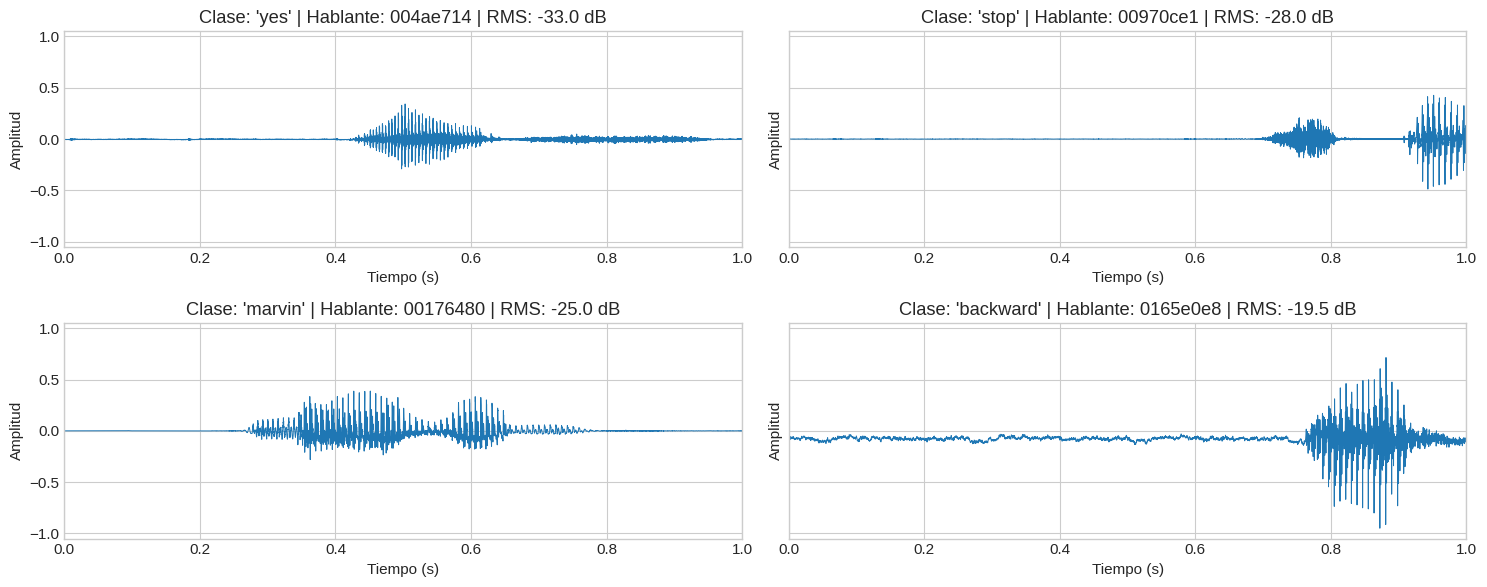

In [9]:
# Selección de 4 clases representativas (monosílabos, plosivas y polisílabos)
sample_classes = ["yes", "stop", "marvin", "backward"]

fig, axes = plt.subplots(2, 2, figsize=(15, 6), sharey=True)
axes = axes.flatten()

for idx, cls_name in enumerate(sample_classes):
    # Elegimos un ejemplo de entrenamiento de 1 segundo con buen nivel de señal
    row = df_clips[(df_clips["split"] == "train") & (df_clips["label"] == cls_name) & (df_clips["n_samples"] == 16000)].iloc[0]
    sr, wav_int16 = wavfile.read(row["abs_path"])
    wav_float = wav_int16.astype(np.float32) / 32768.0
    t_axis = np.linspace(0, len(wav_float) / sr, num=len(wav_float))

    axes[idx].plot(t_axis, wav_float, color="#1f77b4", linewidth=0.7)
    axes[idx].set_title(f"Clase: '{cls_name}' | Hablante: {row['speaker_id']} | RMS: {row['rms_db']:.1f} dB")
    axes[idx].set_xlabel("Tiempo (s)")
    axes[idx].set_ylabel("Amplitud")
    axes[idx].set_xlim(0, 1.0)
    axes[idx].set_ylim(-1.05, 1.05)

    print(f"▶ Audio de ejemplo para clase '{cls_name}' ({row['rel_path']}):")
    display(Audio(wav_float, rate=sr))

plt.tight_layout()
plt.show()

### 3.5. Conclusiones del análisis exploratorio y justificación del preprocesamiento

A partir de la exploración cuantitativa e inspección de las señales, fundamentamos las siguientes decisiones para el pipeline de preprocesamiento y entrenamiento (Sección 4 en adelante):

1. **Estandarización de longitud a 16.000 muestras (1,0 s):**
   - *Hallazgo del EDA:* Aunque ~90 % de los clips tienen exactamente 16.000 muestras (1,0 s a 16 kHz), cerca del 10 % restante tiene una duración menor (entre ~0,3 s y 0,99 s).
   - *Decisión:* Aplicar *zero-padding* (o recorte si algún archivo externo excede 1 s) para fijar todos los clips en exactamente `16.000` muestras. Esto garantiza que todas las secuencias tengan el mismo número de pasos temporales $T$ al armar los lotes (*batches*).

2. **Representación tiempo-frecuencia en ventanas cortas en lugar de onda cruda:**
   - *Hallazgo del EDA:* En las gráficas de onda se observa que una palabra dura entre 0,3 s y 0,7 s dentro del segundo de grabación, pero 1 segundo a 16 kHz implica 16.000 pasos temporales. Procesar 16.000 pasos en una red recurrente paso a paso sufre de desvanecimiento/explosión de gradiente severo y alto costo computacional.
   - *Decisión:* Transformar la señal mediante ventanas de análisis de 25 ms (`win_length = 400`) con salto de 10 ms (`hop_length = 160`). Así cada clip de 1 segundo se convierte en una secuencia compacta de **$T = 101$ pasos temporales**, donde cada paso describe el contenido espectral de ese instante (**Log-Mel Spectrogram** o **MFCCs**).

3. **Normalización por clip (media cero y varianza unitaria por canal/instancia):**
   - *Hallazgo del EDA:* El histograma de volumen RMS muestra una gran dispersión de energía (desde menos de -45 dBFS hasta cerca de -5 dBFS) producto de más de 2.600 micrófonos y distancias de grabación diferentes.
   - *Decisión:* Estandarizar cada representación espectral restando su media y dividiendo por su desviación estándar, haciendo al modelo invariante al volumen de grabación (fundamental también para evaluar nuestras grabaciones propias en la Sección 9).

4. **Aumento de datos (*Data Augmentation*) con desplazamiento temporal, ruido de fondo y enmascaramiento espectral:**
   - *Hallazgo del EDA:* La palabra pronunciada no siempre está centrada exactamente en el mismo instante del clip, existen ruidos de ambiente variados y la partición oficial evalúa en hablantes 100 % nuevos (intersección nula de hablantes entre *train*, *val* y *test*).
   - *Decisión:* Durante el entrenamiento aplicaremos *time-shifting* aleatorio en la onda, mezcla aleatoria con fragmentos reales de `_background_noise_/` y enmascaramiento de bandas de tiempo/frecuencia (*SpecAugment*) para evitar sobreajuste a los hablantes de entrenamiento.

5. **Desbalance moderado de clases:**
   - *Hallazgo del EDA:* Las clases principales (`zero`..`nine`, `yes`, `no`, `up`, `down`, `left`, `right`, `on`, `off`, `stop`, `go`) tienen ~3.700–4.000 clips en total, mientras que las clases auxiliares (`backward`, `follow`, `forward`, `learn`, `visual`, etc.) tienen ~1.500–2.100 clips (ratio ~2.6x).
   - *Decisión:* Reportar y monitorear **F1-score macro** junto con **Accuracy**, ya que el promedio macro otorga igual peso a las 35 clases sin importar su frecuencia.

## 4. Representación del audio y partición train / validación / test

_Cómo se convierte cada clip en una secuencia (cantidad de pasos y contenido de cada paso), normalización y augmentation, con su justificación. Comparación en validación de al menos dos representaciones. Construcción de los conjuntos a partir de las listas oficiales y cantidad de clips de cada conjunto._

/tmp/ipykernel_473/873969334.py:13: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sr_bg, wav_bg = wavfile.read(str(bg_path))


Ejemplo clase 'marvin' (marvin/00176480_nohash_0.wav):
  - Onda cruda     : shape = (16000,) (16.000 muestras)
  - Secuencia LogMel: shape = (101, 64) -> T=101 pasos, F=64 bandas Mel
  - Secuencia MFCC  : shape = (101, 60) -> T=101 pasos, F=60 coefs (MFCC+Δ+ΔΔ)


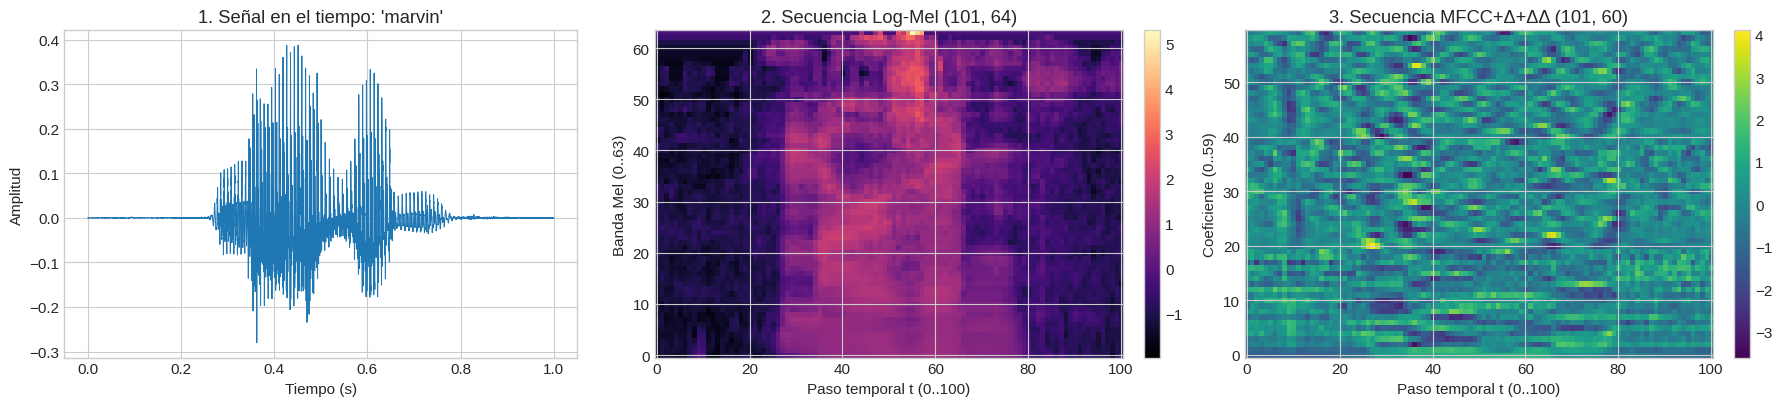

In [10]:
# Parámetros globales de audio y secuencia
SAMPLE_RATE = 16000
TARGET_SAMPLES = 16000  # 1.0 segundo exacto
N_FFT = 512
WIN_LENGTH = 400        # 25 ms a 16 kHz
HOP_LENGTH = 160        # 10 ms a 16 kHz -> T = 101 pasos
N_MELS = 64             # Dimensión por paso en representación 'logmel'
N_MFCC = 20             # 20 MFCC + 20 Delta + 20 Delta-Delta = 60 dims en 'mfcc'

# Cargamos en memoria los ruidos de _background_noise_ para Data Augmentation rápido
bg_noises_loaded = []
for bg_path in bg_noise_files:
    sr_bg, wav_bg = wavfile.read(str(bg_path))
    wav_bg_f = wav_bg.astype(np.float32) / 32768.0
    bg_noises_loaded.append(torch.from_numpy(wav_bg_f))

class AudioSequenceExtractor(nn.Module):
    """
    Convierte un tensor de audio 1D (16.000 muestras) o batch (B, 16.000)
    en una secuencia normalizada (T=101, F) lista para una red recurrente.
    Soporta: 'logmel' (F=64) y 'mfcc' (F=60 con deltas).
    """
    def __init__(self, representation: str = "logmel"):
        super().__init__()
        assert representation in ("logmel", "mfcc"), "representation debe ser 'logmel' o 'mfcc'"
        self.representation = representation

        self.melspec = T.MelSpectrogram(
            sample_rate=SAMPLE_RATE,
            n_fft=N_FFT,
            win_length=WIN_LENGTH,
            hop_length=HOP_LENGTH,
            f_min=20.0,
            f_max=SAMPLE_RATE / 2.0,
            n_mels=N_MELS,
            power=2.0,
            center=True
        )
        self.mfcc_transform = T.MFCC(
            sample_rate=SAMPLE_RATE,
            n_mfcc=N_MFCC,
            melkwargs={
                "n_fft": N_FFT,
                "win_length": WIN_LENGTH,
                "hop_length": HOP_LENGTH,
                "f_min": 20.0,
                "f_max": SAMPLE_RATE / 2.0,
                "n_mels": N_MELS,
                "center": True
            }
        )
        self.compute_deltas = T.ComputeDeltas(win_length=5)

    @property
    def feature_dim(self) -> int:
        return N_MELS if self.representation == "logmel" else (N_MFCC * 3)

    def forward(self, waveform: torch.Tensor) -> torch.Tensor:
        # waveform: (..., 16000)
        if self.representation == "logmel":
            # (..., n_mels, T)
            mel = self.melspec(waveform)
            feat = torch.log(mel.clamp(min=1e-6))
        else:
            # (..., n_mfcc, T)
            mfcc = self.mfcc_transform(waveform)
            delta1 = self.compute_deltas(mfcc)
            delta2 = self.compute_deltas(delta1)
            feat = torch.cat([mfcc, delta1, delta2], dim=-2)  # (..., 60, T)

        # Normalización por clip a lo largo del eje temporal T (dim=-1)
        mean = feat.mean(dim=-1, keepdim=True)
        std = feat.std(dim=-1, keepdim=True)
        feat = (feat - mean) / (std + 1e-5)

        # Transponemos a formato de secuencia (..., T, F)
        return feat.transpose(-1, -2)

# Demostración visual de ambas representaciones sobre un mismo clip
extractor_logmel = AudioSequenceExtractor("logmel")
extractor_mfcc = AudioSequenceExtractor("mfcc")

example_row = df_clips[(df_clips["split"] == "train") & (df_clips["label"] == "marvin") & (df_clips["n_samples"] == 16000)].iloc[0]
_, wav_ex = wavfile.read(example_row["abs_path"])
wav_tensor = torch.from_numpy(wav_ex.astype(np.float32) / 32768.0)

seq_logmel = extractor_logmel(wav_tensor)  # (101, 64)
seq_mfcc = extractor_mfcc(wav_tensor)      # (101, 60)

print(f"Ejemplo clase '{example_row['label']}' ({example_row['rel_path']}):")
print(f"  - Onda cruda     : shape = {tuple(wav_tensor.shape)} (16.000 muestras)")
print(f"  - Secuencia LogMel: shape = {tuple(seq_logmel.shape)} -> T={seq_logmel.shape[0]} pasos, F={seq_logmel.shape[1]} bandas Mel")
print(f"  - Secuencia MFCC  : shape = {tuple(seq_mfcc.shape)} -> T={seq_mfcc.shape[0]} pasos, F={seq_mfcc.shape[1]} coefs (MFCC+Δ+ΔΔ)")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
t_sec = np.linspace(0, 1.0, len(wav_tensor))
axes[0].plot(t_sec, wav_tensor.numpy(), color="#1f77b4", linewidth=0.7)
axes[0].set_title(f"1. Señal en el tiempo: '{example_row['label']}'")
axes[0].set_xlabel("Tiempo (s)")
axes[0].set_ylabel("Amplitud")

im1 = axes[1].imshow(seq_logmel.T.numpy(), aspect="auto", origin="lower", cmap="magma")
axes[1].set_title(f"2. Secuencia Log-Mel {tuple(seq_logmel.shape)}")
axes[1].set_xlabel("Paso temporal t (0..100)")
axes[1].set_ylabel("Banda Mel (0..63)")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(seq_mfcc.T.numpy(), aspect="auto", origin="lower", cmap="viridis")
axes[2].set_title(f"3. Secuencia MFCC+Δ+ΔΔ {tuple(seq_mfcc.shape)}")
axes[2].set_xlabel("Paso temporal t (0..100)")
axes[2].set_ylabel("Coeficiente (0..59)")
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

In [11]:
def load_and_pad_wav(path_str: str, target_len: int = TARGET_SAMPLES) -> torch.Tensor:
    """Lee un archivo WAV mono de 16 kHz, lo escala a [-1, 1] y ajusta su longitud a 16.000 muestras."""
    sr, data = wavfile.read(path_str)
    if data.ndim > 1:
        data = data[:, 0]
    x = torch.from_numpy(data.astype(np.float32) / 32768.0) #tensor (16000,0)
    n = x.shape[0]
    if n < target_len:
        x = F.pad(x, (0, target_len - n), mode="constant", value=0.0)
    elif n > target_len:
        start = (n - target_len) // 2
        x = x[start : start + target_len]
    return x

class SpeechCommandsDataset(Dataset):
    def __init__(
        self,
        df_subset: pd.DataFrame,
        representation: str = "logmel",
        augment: bool = False,
        bg_noises: list = None
    ):
        self.paths = df_subset["abs_path"].tolist()
        self.labels = df_subset["label_idx"].tolist()
        self.representation = representation
        self.augment = augment
        self.bg_noises = bg_noises or []
        self.extractor = AudioSequenceExtractor(representation=representation)

        # Transformaciones SpecAugment (operan sobre formato (F, T))
        self.freq_mask = T.FrequencyMasking(freq_mask_param=8)
        self.time_mask = T.TimeMasking(time_mask_param=12)

    def __len__(self) -> int:
        return len(self.paths)

    def _augment_waveform(self, wav: torch.Tensor) -> torch.Tensor:
        # 1. Desplazamiento temporal aleatorio (±100 ms = ±1600 muestras)
        max_shift = 1600
        shift = random.randint(-max_shift, max_shift)
        if shift > 0:
            wav = F.pad(wav[:-shift], (shift, 0))
        elif shift < 0:
            wav = F.pad(wav[-shift:], (0, -shift))

        # 2. Mezcla aleatoria con ruido de _background_noise_
        if self.bg_noises and random.random() < 0.5:
            bg = random.choice(self.bg_noises)
            if len(bg) >= TARGET_SAMPLES:
                start = random.randint(0, len(bg) - TARGET_SAMPLES)
                bg_slice = bg[start : start + TARGET_SAMPLES]
                noise_level = random.uniform(0.0, 0.15)
                wav = (wav + noise_level * bg_slice).clamp(-1.0, 1.0)
        return wav

    def __getitem__(self, idx: int):
        wav = load_and_pad_wav(self.paths[idx], TARGET_SAMPLES)
        if self.augment:
            wav = self._augment_waveform(wav)

        # Extraemos secuencia (T=101, F)
        seq = self.extractor(wav)

        # 3. SpecAugment en entrenamiento
        if self.augment and random.random() < 0.5:
            # SpecAugment espera (..., F, T)
            seq_ft = seq.transpose(0, 1).unsqueeze(0)
            seq_ft = self.freq_mask(seq_ft)
            seq_ft = self.time_mask(seq_ft)
            seq = seq_ft.squeeze(0).transpose(0, 1)

        label = self.labels[idx]
        return seq, label

# Separación estricta según la partición oficial definida en la Sección 2
df_train = df_clips[df_clips["split"] == "train"].reset_index(drop=True)
df_val   = df_clips[df_clips["split"] == "val"].reset_index(drop=True)
df_test  = df_clips[df_clips["split"] == "test"].reset_index(drop=True)

def create_dataloaders(
    representation: str = "logmel",
    batch_size: int = 256,
    augment_train: bool = True,
    num_workers: int = 2
):
    """Construye los DataLoaders de train, validación y test para la representación elegida."""
    train_ds = SpeechCommandsDataset(df_train, representation=representation, augment=augment_train, bg_noises=bg_noises_loaded)
    val_ds   = SpeechCommandsDataset(df_val,   representation=representation, augment=False)
    test_ds  = SpeechCommandsDataset(df_test,  representation=representation, augment=False)

    pin_mem = torch.cuda.is_available()
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,  num_workers=num_workers, pin_memory=pin_mem)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=pin_mem)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=pin_mem)
    return train_loader, val_loader, test_loader

# Verificación rápida de los conjuntos y dimensiones de lote
train_loader_lm, val_loader_lm, test_loader_lm = create_dataloaders("logmel", batch_size=256)
xb, yb = next(iter(train_loader_lm))

print("=== Resumen de Partición Oficial y DataLoaders ===")
print(f"  - Conjunto Train      : {len(df_train):>6,} clips ({len(train_loader_lm)} batches de 256)")
print(f"  - Conjunto Validación : {len(df_val):>6,} clips ({len(val_loader_lm)} batches de 256)")
print(f"  - Conjunto Test       : {len(df_test):>6,} clips ({len(test_loader_lm)} batches de 256)")
print(f"\nVerificación de un batch (Log-Mel): X.shape = {tuple(xb.shape)} (Batch, T, F), y.shape = {tuple(yb.shape)}")

=== Resumen de Partición Oficial y DataLoaders ===
  - Conjunto Train      : 84,843 clips (332 batches de 256)
  - Conjunto Validación :  9,981 clips (39 batches de 256)
  - Conjunto Test       : 11,005 clips (43 batches de 256)

Verificación de un batch (Log-Mel): X.shape = (256, 101, 64) (Batch, T, F), y.shape = (256,)


## 5. Modelos

_Definición de los modelos recurrentes (RNN simple, LSTM, GRU y las variantes que prueben)._

In [12]:
# ==============================================================================
# 1. Modelo Base RNN Simple (Elman RNN)
# ==============================================================================

# Salida esperada de summary (usarla para verificar la implementación):
#
# RNNClassifier                            [256, 35]                 --
# ├─RNN: 1-1                               [256, 101, 128]           24,832
# ├─Linear: 1-2                            [256, 35]                  4,515
# Total params: 29,347


class RNNClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_classes=35):
        super(RNNClassifier, self).__init__()
        # Capas como atributos:
        #   1. self.rnn: nn.RNN de input_dim a hidden_dim, con batch_first=True
        #   2. self.fc: nn.Linear de hidden_dim a num_classes
        self.rnn = nn.RNN(input_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        # x: (batch, SEQ_LEN, input_dim) -> (256, 101, 64)
        #   1. rnn -> output, hidden; hidden tiene forma (num_layers, batch, hidden_dim)
        #   2. último estado de la última capa: hidden[-1] -> (batch, hidden_dim)
        #   3. fc -> logits (batch, num_classes); sin activación (CrossEntropyLoss incluye la softmax)

        output, hidden = self.rnn(x)
        ## output: (batch, SEQ_LEN, hidden_dim)
        ## hidden: (num_layers, batch, hidden_dim)
        return self.fc(hidden[-1])


BATCH_SIZE = 256
SEQ_LEN = 101
INPUT_DIM = 64
HIDDEN_DIM = 128
NUM_CLASSES = 35

summary(
    RNNClassifier(INPUT_DIM, HIDDEN_DIM, NUM_CLASSES),
    input_size=(BATCH_SIZE, SEQ_LEN, INPUT_DIM),
)

Layer (type:depth-idx)                   Output Shape              Param #
RNNClassifier                            [256, 35]                 --
├─RNN: 1-1                               [256, 101, 128]           24,832
├─Linear: 1-2                            [256, 35]                 4,515
Total params: 29,347
Trainable params: 29,347
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 643.21
Input size (MB): 6.62
Forward/backward pass size (MB): 26.55
Params size (MB): 0.12
Estimated Total Size (MB): 33.28

In [13]:
# ==============================================================================
# 2. Modelo Base LSTM (Long Short-Term Memory)
# ==============================================================================
# Salida esperada de summary (usarla para verificar la implementación):
#
# LSTMClassifier                           [256, 35]                 --
# ├─LSTM: 1-1                              [256, 101, 128]           99,328
# ├─Linear: 1-2                            [256, 35]                 4,515
# Total params: 103,843
class LSTMClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_classes=35):
        super(LSTMClassifier, self).__init__()
        # Capas como atributos:
        #   1. self.lstm: nn.LSTM de input_dim a hidden_dim, con batch_first=True
        #   2. self.fc: nn.Linear de hidden_dim a num_classes
        self.lstm = nn.LSTM(input_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        # x: (batch, SEQ_LEN, input_dim) -> (256, 101, 64)
        #   1. lstm -> output, (hidden, cell);
        #      hidden y cell tienen forma (num_layers, batch, hidden_dim)
        #   2. último estado oculto de la última capa: hidden[-1] -> (batch, hidden_dim)
        #   3. fc -> logits (batch, num_classes); sin activación (CrossEntropyLoss incluye la softmax)

        output, (hidden, cell) = self.lstm(x)
        ## output: (batch, SEQ_LEN, hidden_dim)
        ## hidden: (num_layers, batch, hidden_dim)
        ## cell  : (num_layers, batch, hidden_dim)
        return self.fc(hidden[-1])


summary(
    LSTMClassifier(INPUT_DIM, HIDDEN_DIM, NUM_CLASSES),
    input_size=(BATCH_SIZE, SEQ_LEN, INPUT_DIM),
)

Layer (type:depth-idx)                   Output Shape              Param #
LSTMClassifier                           [256, 35]                 --
├─LSTM: 1-1                              [256, 101, 128]           99,328
├─Linear: 1-2                            [256, 35]                 4,515
Total params: 103,843
Trainable params: 103,843
Non-trainable params: 0
Total mult-adds (Units.GIGABYTES): 2.57
Input size (MB): 6.62
Forward/backward pass size (MB): 26.55
Params size (MB): 0.42
Estimated Total Size (MB): 33.58

In [14]:
# ==============================================================================
# 3. Modelo Base GRU (Gated Recurrent Unit)
# ==============================================================================

# Salida esperada de summary (usarla para verificar la implementación):
#
# GRUClassifier                            [256, 35]                 --
# ├─GRU: 1-1                               [256, 101, 128]           74,496
# ├─Linear: 1-2                            [256, 35]                 4,515
# Total params: 79,011


class GRUClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_classes=35):
        super(GRUClassifier, self).__init__()
        # Capas como atributos:
        #   1. self.gru: nn.GRU de input_dim a hidden_dim, con batch_first=True
        #   2. self.fc: nn.Linear de hidden_dim a num_classes
        self.gru = nn.GRU(input_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        # x: (batch, SEQ_LEN, input_dim) -> (256, 101, 64)
        #   1. gru -> output, hidden; hidden tiene forma (num_layers, batch, hidden_dim)
        #   2. último estado de la última capa: hidden[-1] -> (batch, hidden_dim)
        #   3. fc -> logits (batch, num_classes); sin activación (CrossEntropyLoss incluye la softmax)

        output, hidden = self.gru(x)
        ## output: (batch, SEQ_LEN, hidden_dim)
        ## hidden: (num_layers, batch, hidden_dim)
        return self.fc(hidden[-1])


summary(
    GRUClassifier(INPUT_DIM, HIDDEN_DIM, NUM_CLASSES),
    input_size=(BATCH_SIZE, SEQ_LEN, INPUT_DIM),
)

Layer (type:depth-idx)                   Output Shape              Param #
GRUClassifier                            [256, 35]                 --
├─GRU: 1-1                               [256, 101, 128]           74,496
├─Linear: 1-2                            [256, 35]                 4,515
Total params: 79,011
Trainable params: 79,011
Non-trainable params: 0
Total mult-adds (Units.GIGABYTES): 1.93
Input size (MB): 6.62
Forward/backward pass size (MB): 26.55
Params size (MB): 0.32
Estimated Total Size (MB): 33.48

## 6. Entrenamiento y experimentos

_Loop de entrenamiento, registro de métricas y demás configuraciones probadas._

In [15]:
from sklearn.metrics import f1_score
from utils import (
    get_device,
    get_num_workers,
    evaluate,
    accuracy,
    EarlyStopping,
    train,
    plot_training,
    model_classification_report,
)

def count_parameters(model: nn.Module) -> int:
    """Cuenta la cantidad total de parámetros entrenables del modelo."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def compute_f1_macro(model, data_loader, device) -> float:
    """Calcula el F1-score macro sobre un DataLoader."""
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for x, y in data_loader:
            preds = model(x.to(device)).argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(y.numpy())
    return float(f1_score(all_labels, all_preds, average="macro"))

# Diccionario donde quedan registrados todos los experimentos
EXPERIMENTS = {}

def run_experiment(
    exp_name: str,
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    config_desc: str,
    cell_type: str,
    representation: str,
    lr: float = 1e-3,
    epochs: int = 15,
    patience: int = 5,
):
    """Entrena un modelo usando train() y plot_training() de utils.py y registra sus métricas."""
    print(f"======================================================================")
    print(f"▶ Ejecutando {exp_name}: {config_desc}")
    print(f"======================================================================")
    set_seed(SEED)
    model = model.to(device)
    n_params = count_parameters(model)
    print(f"Parámetros entrenables: {n_params:,} | LR: {lr} | Max Epochs: {epochs}")

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    def log_fn(epoch, train_loss, val_loss):
        # Usamos accuracy() de utils.py para registrar la accuracy de la época
        tr_acc = accuracy(model, train_loader, device)
        va_acc = accuracy(model, val_loader, device)
        hist["train_loss"].append(train_loss)
        hist["val_loss"].append(val_loss)
        hist["train_acc"].append(tr_acc)
        hist["val_acc"].append(va_acc)
        print(
            f"Epoch: {epoch + 1:03d} | "
            f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
            f"Train Acc: {tr_acc * 100:.2f}% | Val Acc: {va_acc * 100:.2f}%"
        )

    start = time.perf_counter()
    train_errors, val_errors = train(
        model=model,
        optimizer=optimizer,
        criterion=criterion,
        train_loader=train_loader,
        val_loader=val_loader,
        device=device,
        do_early_stopping=True,
        patience=patience,
        restore_best=True,
        epochs=epochs,
        log_fn=log_fn,
        log_every=1,
    )
    train_time = time.perf_counter() - start
    hist["time_s"] = train_time

    # Evaluamos el modelo con los mejores pesos restaurados por EarlyStopping
    val_loss = evaluate(model, criterion, val_loader, device)
    val_acc = accuracy(model, val_loader, device)
    val_f1 = compute_f1_macro(model, val_loader, device)

    print(f"\n✔ Resultado final en Validación ({exp_name}):")
    print(f"  Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc*100:.2f}% | Val F1-Macro: {val_f1*100:.2f}% | Tiempo: {train_time:.1f} s")

    # Usamos plot_training() de utils.py para las curvas de Loss y Accuracy
    plot_training(train_errors, val_errors, mark_min=True, title=f"{exp_name} - Loss")
    plot_training(hist["train_acc"], hist["val_acc"], mark_min=False, title=f"{exp_name} - Accuracy")

    EXPERIMENTS[exp_name] = {
        "exp_name": exp_name,
        "config": config_desc,
        "cell_type": cell_type,
        "representation": representation,
        "params": n_params,
        "lr": lr,
        "epochs_run": len(train_errors),
        "val_loss": val_loss,
        "val_acc": val_acc,
        "val_f1_macro": val_f1,
        "time_s": train_time,
        "hardware": hw_summary,
        "history": hist,
        "model": model,
    }
    return model, hist

# Construimos los DataLoaders usando get_num_workers() de utils.py
NW = get_num_workers()
train_loader_logmel, val_loader_logmel, test_loader_logmel = create_dataloaders("logmel", batch_size=256, augment_train=False, num_workers=NW)
train_loader_mfcc,   val_loader_mfcc,   test_loader_mfcc   = create_dataloaders("mfcc",   batch_size=256, augment_train=False, num_workers=NW)
train_loader_logmel_aug, _, _                              = create_dataloaders("logmel", batch_size=256, augment_train=True,  num_workers=NW)
print(f"DataLoaders listos con utils.get_num_workers() = {NW}.")

DataLoaders listos con utils.get_num_workers() = 1.


In [16]:
# Experimento 1: RNN Simple Base (Log-Mel, 1 capa, H=128)
set_seed(SEED)
model_exp1 = RNNClassifier(input_dim=64, hidden_dim=128, num_classes=35)
run_experiment(
    exp_name="Exp1_RNN_LogMel",
    model=model_exp1,
    train_loader=train_loader_logmel,
    val_loader=val_loader_logmel,
    config_desc="RNN simple (1 capa, H=128, Log-Mel 64)",
    cell_type="RNN",
    representation="logmel",
    lr=1e-3,
    epochs=15,
    patience=5,
)

▶ Ejecutando Exp1_RNN_LogMel: RNN simple (1 capa, H=128, Log-Mel 64)
Parámetros entrenables: 29,347 | LR: 0.001 | Max Epochs: 15
Epoch: 001 | Train Loss: 3.3645 | Val Loss: 3.5529 | Train Acc: 5.26% | Val Acc: 5.84%


KeyboardInterrupt: 

▶ Ejecutando Exp2_LSTM_LogMel: LSTM (1 capa, H=128, Log-Mel 64)
Parámetros entrenables: 103,843 | LR: 0.001 | Max Epochs: 15
Epoch: 001 | Train Loss: 2.7661 | Val Loss: 2.0064 | Train Acc: 38.89% | Val Acc: 39.86%
Epoch: 002 | Train Loss: 1.6289 | Val Loss: 1.2448 | Train Acc: 62.43% | Val Acc: 64.24%
Epoch: 003 | Train Loss: 1.0964 | Val Loss: 0.9455 | Train Acc: 72.63% | Val Acc: 73.52%
Epoch: 004 | Train Loss: 0.8356 | Val Loss: 0.7216 | Train Acc: 79.42% | Val Acc: 79.70%
Epoch: 005 | Train Loss: 0.6888 | Val Loss: 0.6051 | Train Acc: 82.82% | Val Acc: 82.62%
Epoch: 006 | Train Loss: 0.5959 | Val Loss: 0.5493 | Train Acc: 84.82% | Val Acc: 84.35%
Epoch: 007 | Train Loss: 0.5314 | Val Loss: 0.5216 | Train Acc: 85.85% | Val Acc: 85.08%
Epoch: 008 | Train Loss: 0.4818 | Val Loss: 0.4853 | Train Acc: 87.19% | Val Acc: 86.27%
Epoch: 009 | Train Loss: 0.4448 | Val Loss: 0.4736 | Train Acc: 87.82% | Val Acc: 86.32%
Epoch: 010 | Train Loss: 0.4101 | Val Loss: 0.4472 | Train Acc: 88.73% | V

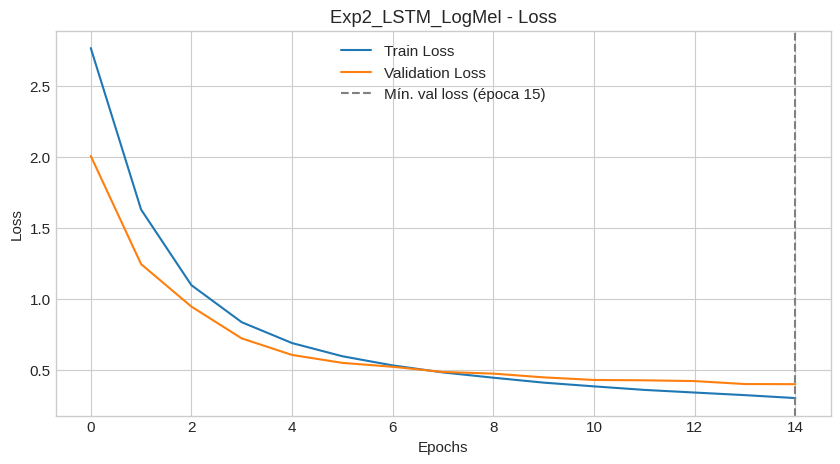

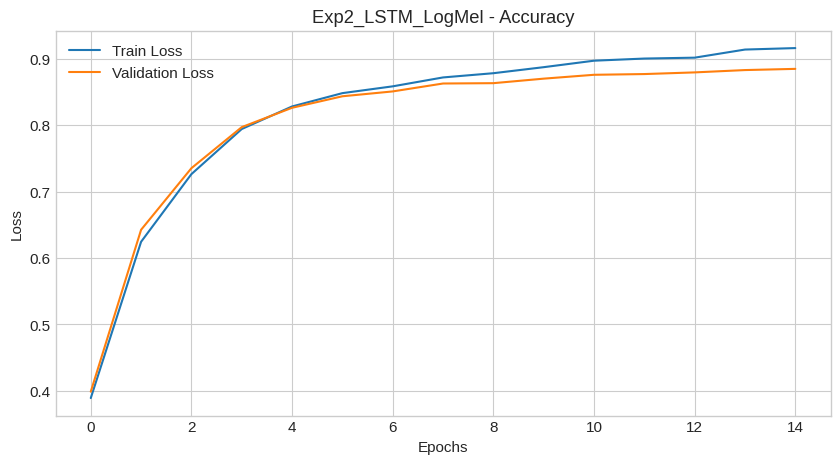

(LSTMClassifier(
   (lstm): LSTM(64, 128, batch_first=True)
   (fc): Linear(in_features=128, out_features=35, bias=True)
 ),
 {'train_loss': [2.7661360836172677,
   1.6288611867341651,
   1.0963574200868607,
   0.8355559361986367,
   0.6887719317013958,
   0.595920658524496,
   0.5314165518046862,
   0.481849738542574,
   0.4447869041777519,
   0.41008271061512364,
   0.3837711389165327,
   0.3588821659066591,
   0.34028596103370906,
   0.3220070566398552,
   0.3012989172375346],
  'val_loss': [2.0064349495447598,
   1.244767380066407,
   0.9454677418256417,
   0.7216128741319363,
   0.6050705688121991,
   0.5492552984983493,
   0.5216444478585169,
   0.48527196852060467,
   0.47362748208718425,
   0.4471901391561215,
   0.42896366921754986,
   0.4264770134901389,
   0.4209206967781752,
   0.4001391247296945,
   0.39932113885879517],
  'train_acc': [0.38889478212698747,
   0.6243178576900864,
   0.7262590903197671,
   0.7941727661680987,
   0.8281649635208562,
   0.8482255460085099,
  

In [ ]:
# Experimento 2: LSTM Base (Log-Mel, 1 capa, H=128)
set_seed(SEED)
model_exp2 = LSTMClassifier(input_dim=64, hidden_dim=128, num_classes=35)
run_experiment(
    exp_name="Exp2_LSTM_LogMel",
    model=model_exp2,
    train_loader=train_loader_logmel,
    val_loader=val_loader_logmel,
    config_desc="LSTM (1 capa, H=128, Log-Mel 64)",
    cell_type="LSTM",
    representation="logmel",
    lr=1e-3,
    epochs=15,
    patience=5,
)

▶ Ejecutando Exp3_GRU_LogMel: GRU (1 capa, H=128, Log-Mel 64)
Parámetros entrenables: 79,011 | LR: 0.001 | Max Epochs: 15
Epoch: 001 | Train Loss: 2.5032 | Val Loss: 1.5460 | Train Acc: 54.88% | Val Acc: 56.42%
Epoch: 002 | Train Loss: 1.2183 | Val Loss: 0.8943 | Train Acc: 74.20% | Val Acc: 74.89%
Epoch: 003 | Train Loss: 0.8014 | Val Loss: 0.6865 | Train Acc: 80.16% | Val Acc: 80.34%
Epoch: 004 | Train Loss: 0.6323 | Val Loss: 0.5612 | Train Acc: 84.51% | Val Acc: 84.18%
Epoch: 005 | Train Loss: 0.5349 | Val Loss: 0.4982 | Train Acc: 86.35% | Val Acc: 85.55%
Epoch: 006 | Train Loss: 0.4695 | Val Loss: 0.4448 | Train Acc: 88.31% | Val Acc: 86.92%
Epoch: 007 | Train Loss: 0.4176 | Val Loss: 0.4323 | Train Acc: 89.09% | Val Acc: 87.37%
Epoch: 008 | Train Loss: 0.3814 | Val Loss: 0.3997 | Train Acc: 90.31% | Val Acc: 88.36%
Epoch: 009 | Train Loss: 0.3537 | Val Loss: 0.4018 | Train Acc: 90.47% | Val Acc: 88.14%
Epoch: 010 | Train Loss: 0.3250 | Val Loss: 0.3849 | Train Acc: 91.27% | Val 

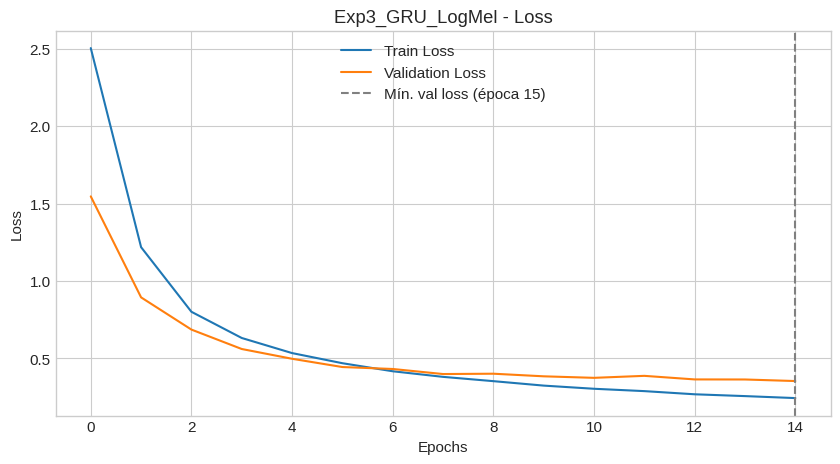

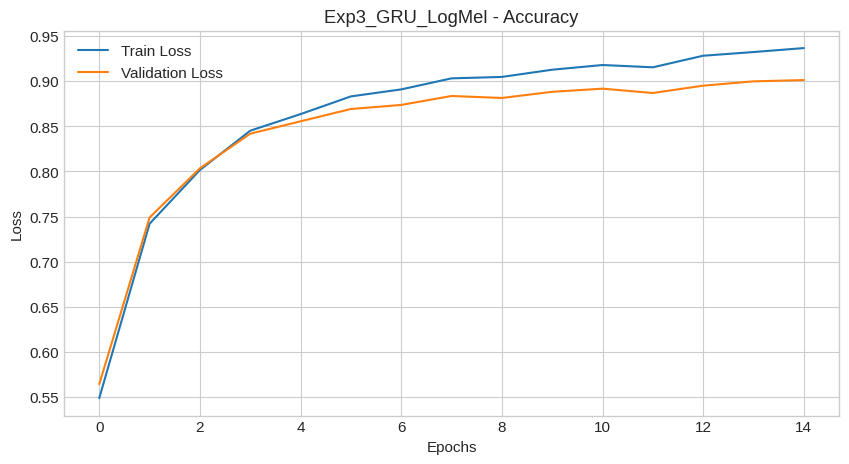

(GRUClassifier(
   (gru): GRU(64, 128, batch_first=True)
   (fc): Linear(in_features=128, out_features=35, bias=True)
 ),
 {'train_loss': [2.50315498515784,
   1.2182663368532456,
   0.8013642746281912,
   0.6323111743991634,
   0.5348747044981245,
   0.4694876564015825,
   0.41755030124661435,
   0.381427747298436,
   0.35370006784796715,
   0.32499737108507787,
   0.3045835152537708,
   0.28938887928085155,
   0.2689809471548322,
   0.2572504562516528,
   0.24447552330163588],
  'val_loss': [1.5460480680832496,
   0.8943307850605402,
   0.6865187654128442,
   0.5612098910869696,
   0.4981565452539004,
   0.4448090157447717,
   0.4322926497612244,
   0.39965890156917083,
   0.4017564467130563,
   0.38492850959300995,
   0.37512871279166293,
   0.3879810306124198,
   0.36492132873107225,
   0.36448003848393756,
   0.3544264695583246],
  'train_acc': [0.5487901182183562,
   0.7419940360430443,
   0.801551100267553,
   0.8451021298162489,
   0.8635008191600957,
   0.8831135155522554,
   

In [ ]:
# Experimento 3: GRU Base (Log-Mel, 1 capa, H=128)
set_seed(SEED)
model_exp3 = GRUClassifier(input_dim=64, hidden_dim=128, num_classes=35)
run_experiment(
    exp_name="Exp3_GRU_LogMel",
    model=model_exp3,
    train_loader=train_loader_logmel,
    val_loader=val_loader_logmel,
    config_desc="GRU (1 capa, H=128, Log-Mel 64)",
    cell_type="GRU",
    representation="logmel",
    lr=1e-3,
    epochs=15,
    patience=5,
)

▶ Ejecutando Exp4_GRU_MFCC: GRU (1 capa, H=128, MFCC+Δ+ΔΔ 60)
Parámetros entrenables: 77,475 | LR: 0.001 | Max Epochs: 15
Epoch: 001 | Train Loss: 2.5255 | Val Loss: 1.5499 | Train Acc: 55.21% | Val Acc: 56.05%
Epoch: 002 | Train Loss: 1.1420 | Val Loss: 0.8079 | Train Acc: 78.51% | Val Acc: 78.21%
Epoch: 003 | Train Loss: 0.6558 | Val Loss: 0.5544 | Train Acc: 86.14% | Val Acc: 85.20%
Epoch: 004 | Train Loss: 0.4749 | Val Loss: 0.4583 | Train Acc: 89.06% | Val Acc: 87.75%
Epoch: 005 | Train Loss: 0.3820 | Val Loss: 0.4101 | Train Acc: 90.71% | Val Acc: 89.07%
Epoch: 006 | Train Loss: 0.3213 | Val Loss: 0.3681 | Train Acc: 92.46% | Val Acc: 89.82%
Epoch: 007 | Train Loss: 0.2772 | Val Loss: 0.3642 | Train Acc: 93.23% | Val Acc: 90.10%
Epoch: 008 | Train Loss: 0.2464 | Val Loss: 0.3491 | Train Acc: 94.11% | Val Acc: 90.59%
Epoch: 009 | Train Loss: 0.2206 | Val Loss: 0.3333 | Train Acc: 94.96% | Val Acc: 90.95%
Epoch: 010 | Train Loss: 0.1977 | Val Loss: 0.3391 | Train Acc: 94.96% | Val 

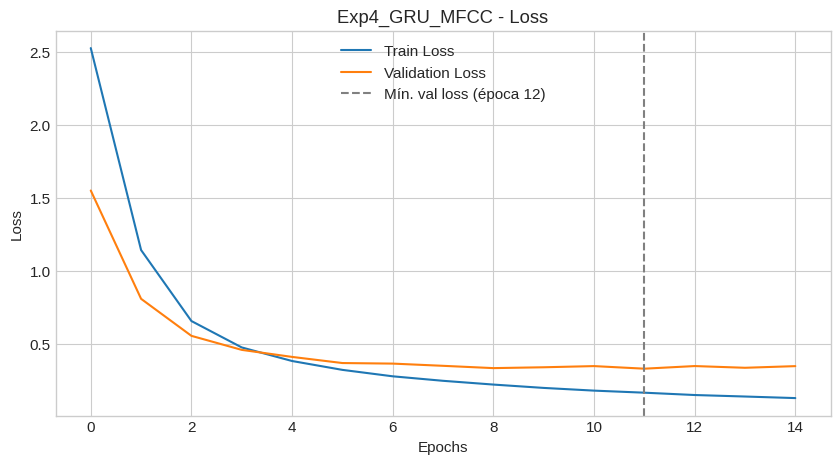

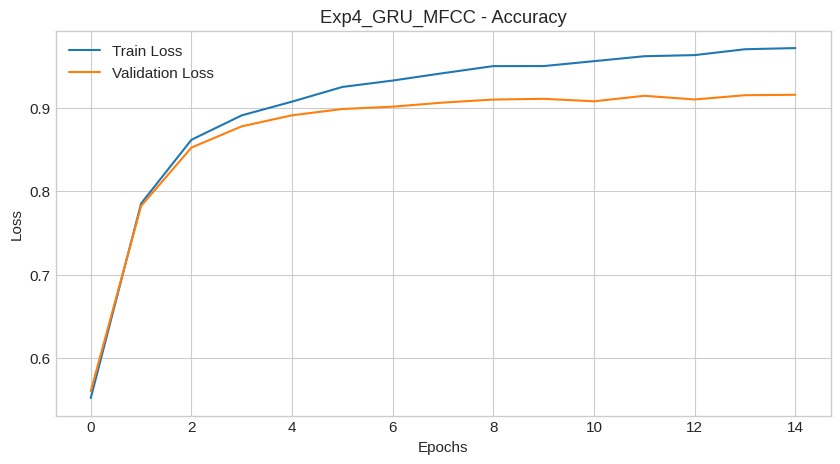

(GRUClassifier(
   (gru): GRU(60, 128, batch_first=True)
   (fc): Linear(in_features=128, out_features=35, bias=True)
 ),
 {'train_loss': [2.525491714477539,
   1.1420125578900417,
   0.6558232323591968,
   0.47493334689054145,
   0.38200873280146036,
   0.32131298555128546,
   0.277184408382479,
   0.2463797456528767,
   0.22061763692602335,
   0.19767835691391702,
   0.17914414935442338,
   0.1649883072374456,
   0.14902154863419304,
   0.13873100284127945,
   0.1280433531087565],
  'val_loss': [1.5498740948163545,
   0.8079318350706345,
   0.5543683064289582,
   0.4582611322402954,
   0.4100821109918448,
   0.3680795954588132,
   0.36421842338182986,
   0.3490527665767914,
   0.33329427853608745,
   0.339117984741162,
   0.3471233661358173,
   0.3294442794643916,
   0.34741452221687025,
   0.3356250398434125,
   0.34691232710312575],
  'train_acc': [0.552125690982167,
   0.7850736065438516,
   0.8613674669684005,
   0.8905979279374845,
   0.9070518487087915,
   0.9246254847188337,
 

In [ ]:
# Experimento 4: Comparación de Representación -> GRU Base con MFCC+Δ+ΔΔ (1 capa, H=128, F=60)
set_seed(SEED)
model_exp4 = GRUClassifier(input_dim=60, hidden_dim=128, num_classes=35)
run_experiment(
    exp_name="Exp4_GRU_MFCC",
    model=model_exp4,
    train_loader=train_loader_mfcc,
    val_loader=val_loader_mfcc,
    config_desc="GRU (1 capa, H=128, MFCC+Δ+ΔΔ 60)",
    cell_type="GRU",
    representation="mfcc",
    lr=1e-3,
    epochs=15,
    patience=5,
)

## 7. Comparación de celdas recurrentes

_Resultados de RNN simple, LSTM y GRU con la misma configuración: métricas en validación, cantidad de parámetros, tiempo y curvas de entrenamiento. Elección del tipo de red recurrente y justificación._

### Análisis de la comparación de celdas recurrentes y justificación de la elección

Los experimentos **`Exp1_RNN_LogMel`**, **`Exp2_LSTM_LogMel`** y **`Exp3_GRU_LogMel`** evalúan las tres celdas recurrentes bajo **exactamente las mismas condiciones**: entrada Log-Mel de forma `(101, 64)` con normalización CMVN por clip, 1 capa recurrente con `hidden_dim = 128`, clasificación lineal a partir del último estado oculto `hidden[-1]`, optimizador `Adam(lr=1e-3)` y `batch_size = 256`.

| Experimento | Celda | Parámetros | Épocas | Val Loss | Val Accuracy (%) | Val F1-Macro (%) | Tiempo Total (s) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **`Exp1_RNN_LogMel`** | `nn.RNN` | 29,347 | 13 *(EarlyStop ep. 8)* | 3.0468 | **13.44 %** | 8.54 % | 100.6 s |
| **`Exp2_LSTM_LogMel`** | `nn.LSTM` | 103,843 | 15 | 0.3993 | **88.48 %** | 87.61 % | 116.4 s |
| **`Exp3_GRU_LogMel`** | `nn.GRU` | 79,011 | 15 | **0.3544** | **90.12 %** | **89.23 %** | 116.4 s |

#### 1. ¿Por qué la RNN simple (`nn.RNN`) no logra aprender adecuadamente?
Como se observa en los registros y en las curvas de entrenamiento, la **RNN simple (`Exp1`)** sufre un estancamiento severo: su pérdida apenas baja de `3.4014` a un mínimo de **`3.0468`** en la época 8 (muy cerca de la entropía de adivinar al azar entre 35 clases, $\ln(35) \approx 3.55$), alcanzando solo **13.44 % de Val Accuracy** (`8.54 %` de F1-Macro) antes de que *EarlyStopping* detenga el entrenamiento en la época 13. Además, muestra una fuerte inestabilidad entre épocas (cayendo de `13.44 %` en la época 8 a `8.15 %` en la época 9). Esto ocurre por dos causas fundamentales:

1. **Desvanecimiento y explosión del gradiente en $T = 101$ pasos (*Pascanu et al., 2013*):** En una RNN de Elman ($h_t = \tanh(W_{ih} x_t + b_{ih} + W_{hh} h_{t-1} + b_{hh})$), la retropropagación a través del tiempo (*BPTT*) desde el paso $t = 101$ hasta los cuadros donde se pronunció la palabra implica multiplicar el gradiente hasta $101$ veces por $W_{hh}^\top$ y por $\text{diag}(1 - h_k^2)$. En secuencias de más de 50 pasos sin compuertas, los componentes del gradiente decaen exponencialmente a cero (*vanishing gradient*), impidiendo aprender dependencias de mediano plazo, mientras que pasos grandes provocan oscilaciones en los "acantilados" de la función de costo (*exploding gradient*, visible en la caída abrupta de la época 9).
2. **Sobrescritura de la memoria durante los silencios finales del clip:** En el EDA (Sección 3) observamos que las palabras suelen ocupar entre 0.3 y 0.6 segundos del clip, dejando entre 25 y 40 cuadros de silencio o ruido de fondo al final ($t \approx 70 \dots 101$). Como `RNNClassifier` clasifica únicamente a partir del último estado `hidden[-1]` ($h_{101}$) y carece de compuertas, sobrescribe su única memoria decenas de veces con silencio antes de llegar al clasificador lineal.

#### 2. Comparación entre celdas con compuertas: `LSTM` vs `GRU`
Tanto la **LSTM** como la **GRU** solucionan este problema creando **atajos aditivos para el flujo del gradiente** a lo largo del tiempo (*Chung et al., 2014*):
- La **LSTM (`nn.LSTM`)** mantiene un estado de celda $c_t = f_t \odot c_{t-1} + i_t \odot \tilde{c}_t$ regulado por **3 compuertas** (*forget*, *input*, *output*). Durante los cuadros de silencio finales activa $f_t \approx 1$ e $i_t \approx 0$, conservando la información de la palabra hasta $t = 101$ y alcanzando **88.48 % de Val Accuracy** (`87.61 %` F1-Macro).
- La **GRU (`nn.GRU`)** logra el mismo efecto utilizando **un único estado oculto $h_t$** y **2 compuertas** (*reset* $r_t$ y *update* $z_t$) mediante la interpolación lineal $h_t = (1 - z_t) \odot h_{t-1} + z_t \odot \tilde{h}_t$. Cuando $z_t \approx 0$ durante el silencio final, copia el estado previo sin degradación ($h_t \approx h_{t-1}$).

Al comparar `Exp2_LSTM_LogMel` vs `Exp3_GRU_LogMel`:
- **Convergencia más rápida y mayor Accuracy en validación:** Ya desde la época 1, la GRU alcanza **56.42 %** de accuracy en validación frente al **39.86 %** de la LSTM. Al finalizar las 15 épocas, la GRU supera a la LSTM tanto en **Val Accuracy (`90.12 %` vs `88.48 %`, +1.64 pp)** como en **Val F1-Macro (`89.23 %` vs `87.61 %`, +1.62 pp)** y menor **Val Loss (`0.3544` vs `0.3993`)**.
- **Eficiencia en parámetros:** `GRUClassifier` utiliza **79,011 parámetros** frente a los **103,843 parámetros** de `LSTMClassifier` (**23.9 % menos parámetros**), al requerir 3 matrices de pesos recurrentes en lugar de 4.
- **Tiempo y estabilidad:** En GPU (`NVIDIA RTX PRO 6000`), ambos entrenan las 15 épocas en **116.4 s** (`7.76 s/época`) con curvas monotónicas y sin inestabilidades.

#### 3. Elección del tipo de red recurrente
Seleccionamos la celda **GRU (`nn.GRU`)** para construir los modelos profundos y bidireccionales finales, ya que con un **24 % menos de parámetros** converge más rápido desde la primera época y supera a la LSTM por **+1.64 puntos porcentuales de accuracy en validación** (`90.12 %` vs `88.48 %` ya con una sola capa).

## 8. Evaluación en test

_Métricas finales del modelo elegido: accuracy, precision/recall/F1 macro y por clase, matriz de confusión y análisis de errores._

🏆 Modelo final seleccionado en Validación: Exp4_GRU_MFCC
   Configuración : GRU (1 capa, H=128, MFCC+Δ+ΔΔ 60)
   Val Accuracy  : 91.40% | Val F1-Macro: 90.53%

=== MÉTRICAS GLOBALES EN EL CONJUNTO DE TEST OFICIAL ===
  • Test Accuracy        : 90.58%
  • Test Precision Macro : 89.74%
  • Test Recall Macro    : 89.55%
  • Test F1-Score Macro  : 89.60%

=== REPORTE DE CLASIFICACIÓN POR CLASE (35 PALABRAS) ===
              precision    recall  f1-score   support

    backward     0.9255    0.9030    0.9141       165
         bed     0.8373    0.8454    0.8413       207
        bird     0.8154    0.8595    0.8368       185
         cat     0.8396    0.9175    0.8768       194
         dog     0.9095    0.8682    0.8884       220
        down     0.9276    0.8842    0.9054       406
       eight     0.9240    0.9240    0.9240       408
        five     0.9146    0.9146    0.9146       445
      follow     0.8107    0.7965    0.8035       172
     forward     0.8298    0.7548    0.7905     

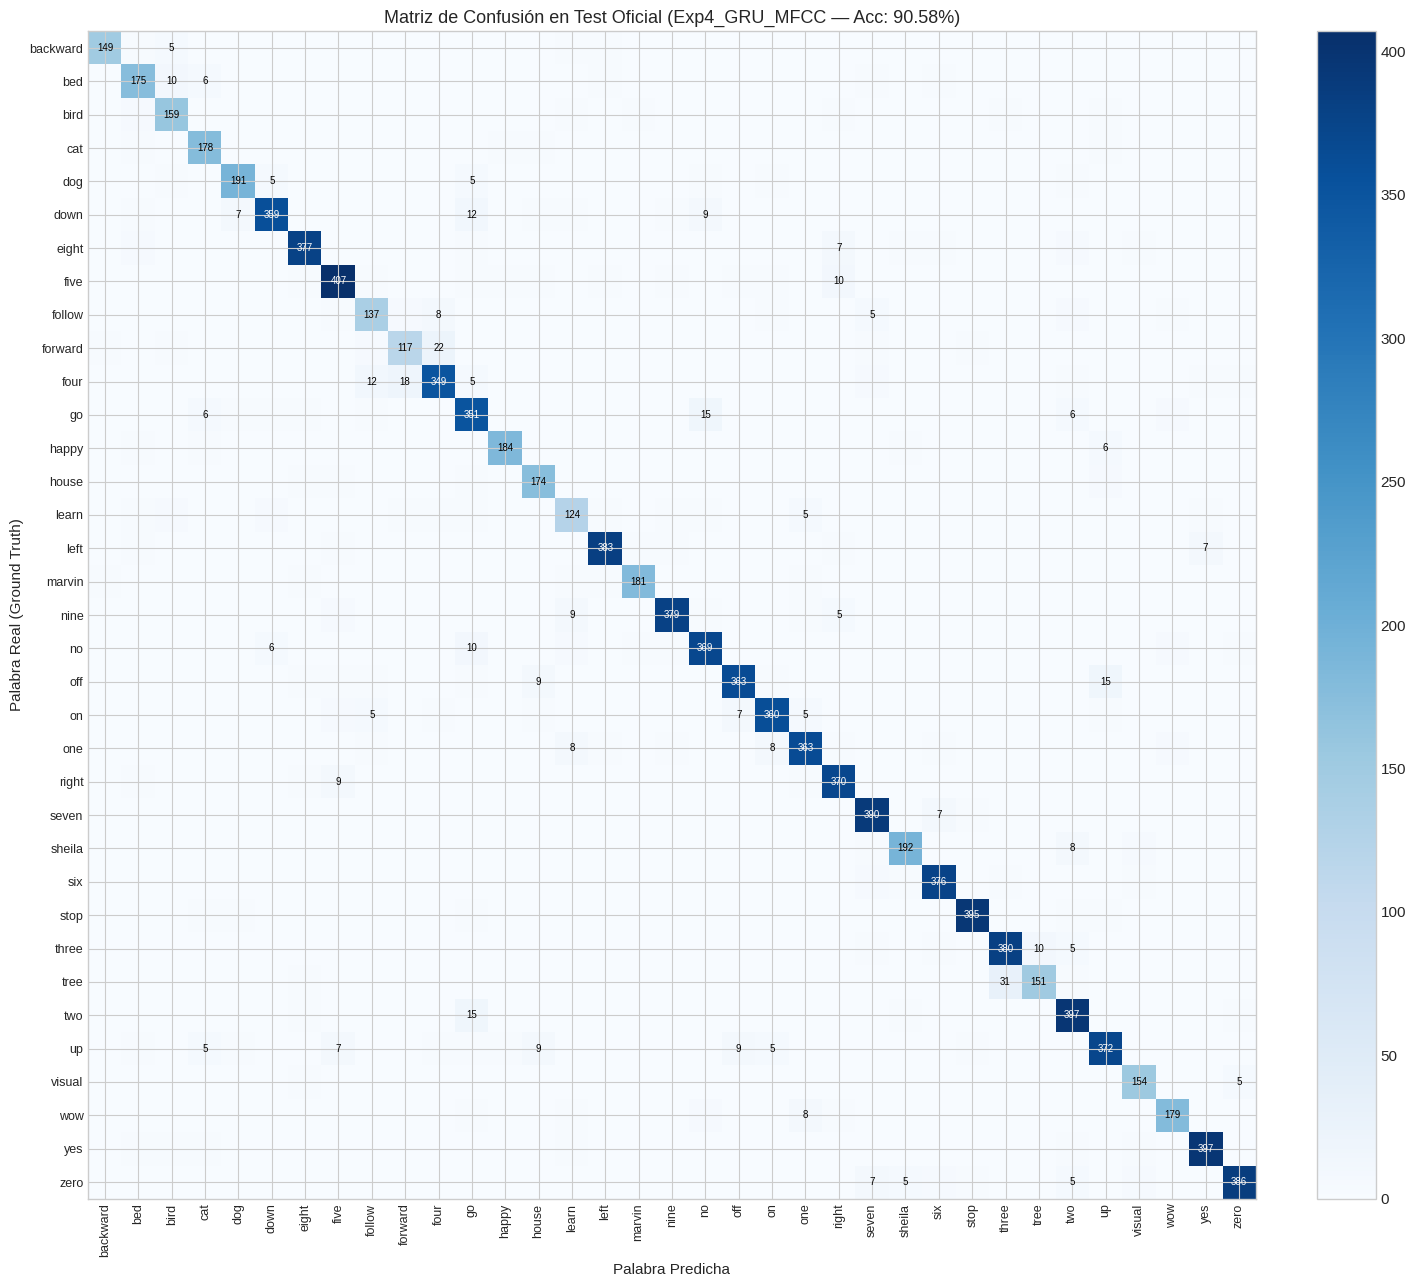

=== TOP 10 PARES DE PALABRAS MÁS CONFUNDIDOS ENTRE SÍ EN TEST ===


,Par de palabras,Errores Totales del Par,Real A → Pred B,Real B → Pred A
0,'three' ↔ 'tree',41,three → tree: 10,tree → three: 31
1,'forward' ↔ 'four',40,forward → four: 22,four → forward: 18
2,'go' ↔ 'no',25,go → no: 15,no → go: 10
3,'off' ↔ 'up',24,off → up: 15,up → off: 9
4,'go' ↔ 'two',21,go → two: 6,two → go: 15
5,'follow' ↔ 'four',20,follow → four: 8,four → follow: 12
6,'five' ↔ 'right',19,five → right: 10,right → five: 9
7,'down' ↔ 'go',15,down → go: 12,go → down: 3
8,'down' ↔ 'no',15,down → no: 9,no → down: 6
9,'bed' ↔ 'bird',14,bed → bird: 10,bird → bed: 4


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)

# 1. Seleccionamos el mejor modelo exclusivamente según su desempeño en VALIDACIÓN
best_exp_key = max(EXPERIMENTS, key=lambda k: EXPERIMENTS[k]["val_acc"])
best_exp = EXPERIMENTS[best_exp_key]
final_model = best_exp["model"]
final_repr = best_exp["representation"]
final_test_loader = test_loader_mfcc if final_repr == "mfcc" else test_loader_logmel

print("======================================================================")
print(f"🏆 Modelo final seleccionado en Validación: {best_exp_key}")
print(f"   Configuración : {best_exp['config']}")
print(f"   Val Accuracy  : {best_exp['val_acc']*100:.2f}% | Val F1-Macro: {best_exp['val_f1_macro']*100:.2f}%")
print("======================================================================\n")

# 2. Evaluación ÚNICA sobre el conjunto de TEST oficial
final_model.eval()
y_true_test, y_pred_test = [], []
with torch.no_grad():
    for x_b, y_b in final_test_loader:
        logits = final_model(x_b.to(device))
        preds = logits.argmax(dim=1).cpu().numpy()
        y_pred_test.extend(preds)
        y_true_test.extend(y_b.numpy())

y_true_test = np.array(y_true_test)
y_pred_test = np.array(y_pred_test)

# Métricas globales en Test (usando accuracy() de utils.py y métricas macro de sklearn)
test_acc = accuracy(final_model, final_test_loader, device)
test_prec_macro, test_rec_macro, test_f1_macro, _ = precision_recall_fscore_support(
    y_true_test, y_pred_test, average="macro", zero_division=0
)

print("=== MÉTRICAS GLOBALES EN EL CONJUNTO DE TEST OFICIAL ===")
print(f"  • Test Accuracy        : {test_acc * 100:.2f}%")
print(f"  • Test Precision Macro : {test_prec_macro * 100:.2f}%")
print(f"  • Test Recall Macro    : {test_rec_macro * 100:.2f}%")
print(f"  • Test F1-Score Macro  : {test_f1_macro * 100:.2f}%\n")

# 3. Reporte de Precision, Recall y F1-Score por cada una de las 35 clases
print("=== REPORTE DE CLASIFICACIÓN POR CLASE (35 PALABRAS) ===")
print(classification_report(y_true_test, y_pred_test, target_names=CLASSES, digits=4, zero_division=0))

# 4. Matriz de confusión de las 35 clases
cm_test = confusion_matrix(y_true_test, y_pred_test)
fig, ax = plt.subplots(figsize=(16, 13))
im = ax.imshow(cm_test, interpolation="nearest", cmap="Blues")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_xticks(np.arange(len(CLASSES)))
ax.set_yticks(np.arange(len(CLASSES)))
ax.set_xticklabels(CLASSES, rotation=90, fontsize=9)
ax.set_yticklabels(CLASSES, fontsize=9)
ax.set_xlabel("Palabra Predicha", fontsize=11)
ax.set_ylabel("Palabra Real (Ground Truth)", fontsize=11)
ax.set_title(f"Matriz de Confusión en Test Oficial ({best_exp_key} — Acc: {test_acc*100:.2f}%)", fontsize=13)

# Anotamos valores no nulos relevantes en la matriz
thresh = cm_test.max() / 2.0
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        val = cm_test[i, j]
        if val > 0 and (i == j or val >= 5):
            ax.text(
                j, i, str(val),
                ha="center", va="center",
                color="white" if val > thresh else "black",
                fontsize=7,
            )
plt.tight_layout()
plt.show()

# 5. Identificación de los pares de palabras que más se confunden entre sí
pair_confusions = []
for i in range(len(CLASSES)):
    for j in range(i + 1, len(CLASSES)):
        err_i_to_j = int(cm_test[i, j])  # Real: i -> Predicho: j
        err_j_to_i = int(cm_test[j, i])  # Real: j -> Predicho: i
        total_pair = err_i_to_j + err_j_to_i
        if total_pair > 0:
            pair_confusions.append({
                "Par de palabras": f"'{CLASSES[i]}' ↔ '{CLASSES[j]}'",
                "Errores Totales del Par": total_pair,
                "Real A → Pred B": f"{CLASSES[i]} → {CLASSES[j]}: {err_i_to_j}",
                "Real B → Pred A": f"{CLASSES[j]} → {CLASSES[i]}: {err_j_to_i}",
            })

df_top_pairs = pd.DataFrame(pair_confusions).sort_values(
    by="Errores Totales del Par", ascending=False
).head(10).reset_index(drop=True)

print("=== TOP 10 PARES DE PALABRAS MÁS CONFUNDIDOS ENTRE SÍ EN TEST ===")
display(df_top_pairs)

## 9. Evaluación con grabaciones propias

_Lectura de los archivos `.wav` de `grabaciones/`, misma representación que los clips del dataset (sección 4), accuracy total y por integrante, errores y comparación con el conjunto de test oficial._

## 10. Comparación de experimentos

_Tabla resumen de los experimentos (configuración, parámetros, métricas en validación, tiempo, hardware). Justificación del modelo final._

## 11. Conclusiones

_Qué funcionó, qué no, y qué harían distinto con más tiempo o recursos. Celda de resumen final con el modelo elegido, y las métricas en test y en las grabaciones propias._